In [ ]:
########################################
## COLAB CLONE REPOSITORY FROM GITHUB ##
########################################

## Note: only run this section if you are running the code in Google Colab and want to clone the repository from GitHub

## Clone GitHub repository and change work directory
!git clone https://github.com/willembonnaffe/mbipm
%cd mbipm

#
###

In [ ]:
##############################
## COLAB MOUNT GOOGLE DRIVE ##
##############################

## Note: only run this section if you are running the code in Google Colab and want to mount Google Drive

from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/my-files/projects/yem # Change path to match local repository

#
###

In [1]:
##############
## INITIATE ##
##############

## Imports
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import seaborn as sns
import yaml
import os

## Import modules
from f_YEM_V1_14_2025_10_10 import pdf
from f_YEM_V1_14_2025_10_10 import f_normal
from f_YEM_V1_14_2025_10_10 import YellowstoneEcosystemModel
from f_YEM_V1_14_2025_10_10 import plot_model

## Set the device to MPS if available
device = torch.device("mps" if torch.backends.mps.is_built() else "cpu")
device = "cpu" # Force cpu for now
print(device)

## Global variables
NBCODE = "C4a"
SAVEFIGS = True # Set to False for colab

## Figure parameters
plt.rcParams['figure.dpi'] = 100
FIGSIZE = (6,4)
custom_params = {"axes.spines.right": False, "axes.spines.top": False, 'axes.facecolor':'whitesmoke'}
sns.set_theme(style="ticks", rc=custom_params)

## Font
PAPER_FORMATTING = False
if PAPER_FORMATTING == True:
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['Times New Roman']
    plt.rcParams['font.size'] = 14
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.rm'] = 'Times New Roman'
    plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
    plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

#
###

cpu


In [2]:
####################
## INITIATE MODEL ##
####################

## Model
model = YellowstoneEcosystemModel('parameters-apriori-V1-14-2025-10-10.yaml')

## Load the YAML file
with open('initial-conditions-apriori-V1-14-2025-10-10.yaml', 'r') as file:
    initial_conditions = yaml.safe_load(file)

## Convert to tensors
Dt0 = torch.tensor(initial_conditions['Dt0'], dtype=torch.float64)
Bt0 = torch.tensor(initial_conditions['Bt0'], dtype=torch.float64)
Pt0 = torch.tensor(initial_conditions['Pt0'], dtype=torch.float64)
Gt0 = torch.tensor(initial_conditions['Gt0'], dtype=torch.float64)
NNt0 = torch.tensor(initial_conditions['NNt0'], dtype=torch.float64)
NNNzt0 = torch.tensor(initial_conditions['NNNzt0'], dtype=torch.float64)

## Load settings
with open('settings-apriori-V1-14-2025-10-10.yaml', 'r') as file:
    settings = yaml.safe_load(file)

## Convert to tensor
zzmax = torch.tensor(settings['zzmax'], dtype=torch.float64)
zzz_len = settings['zzz_len']

#
###

0.25s


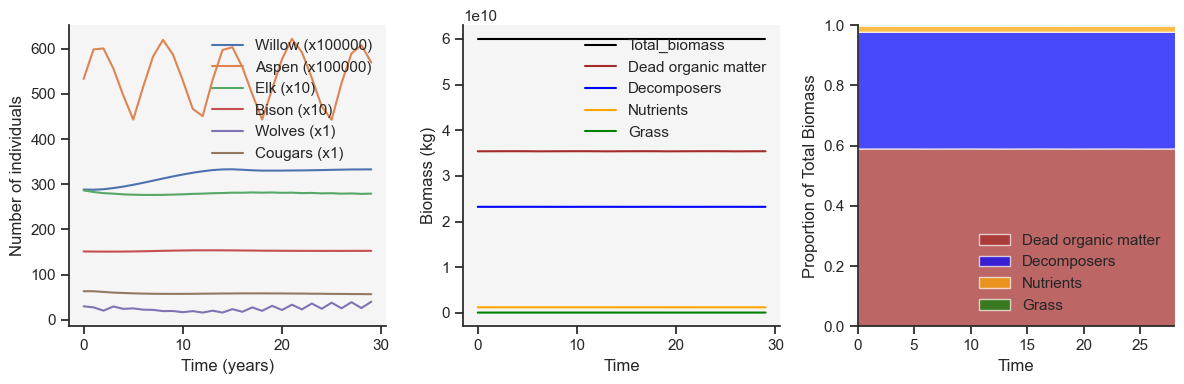

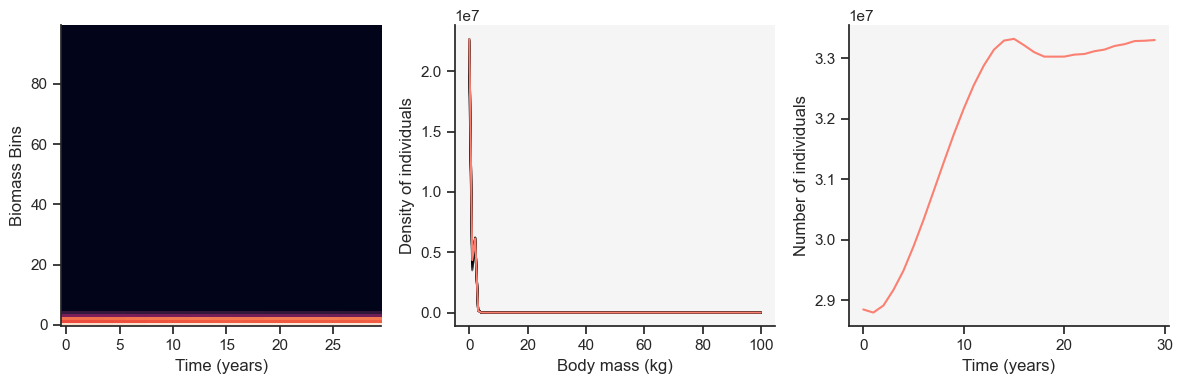

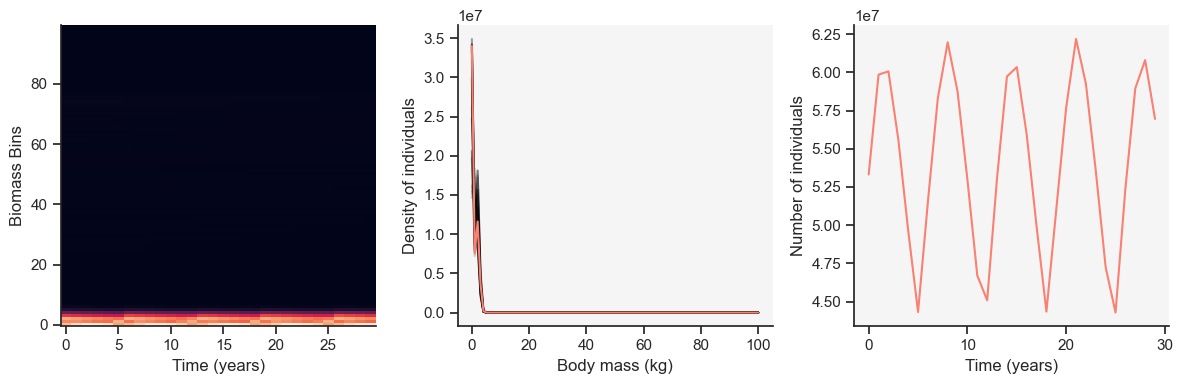

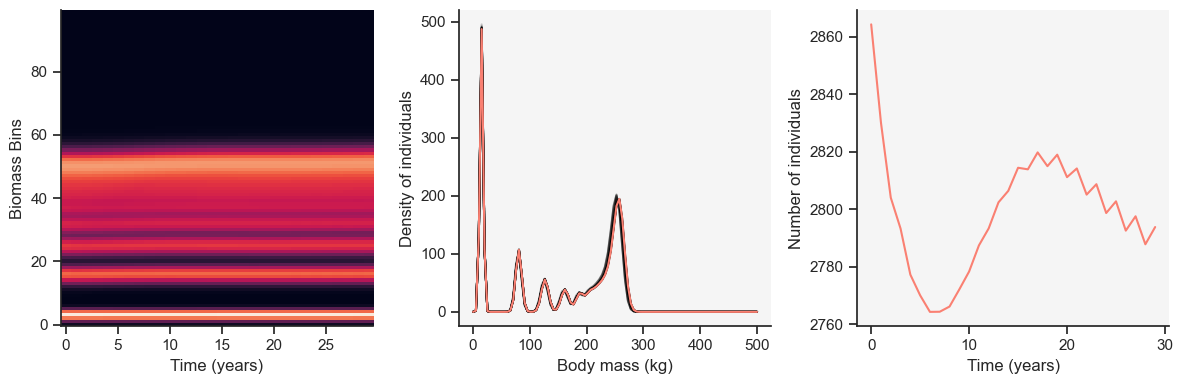

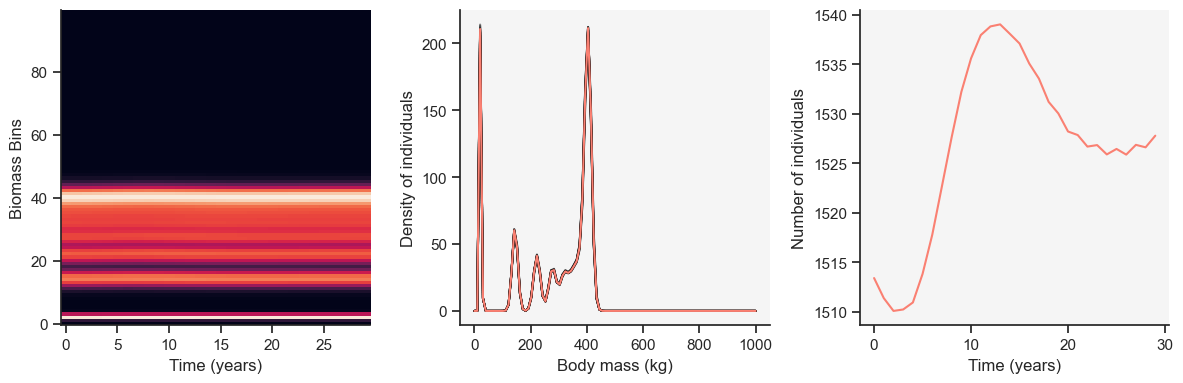

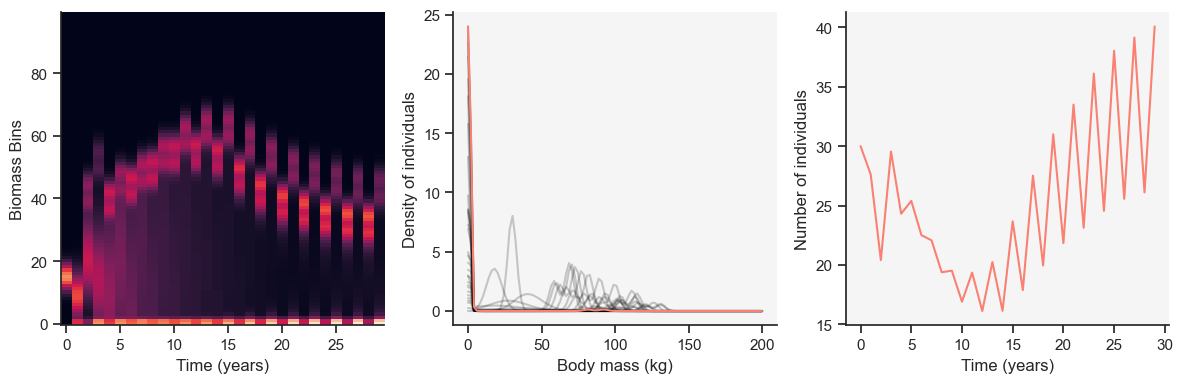

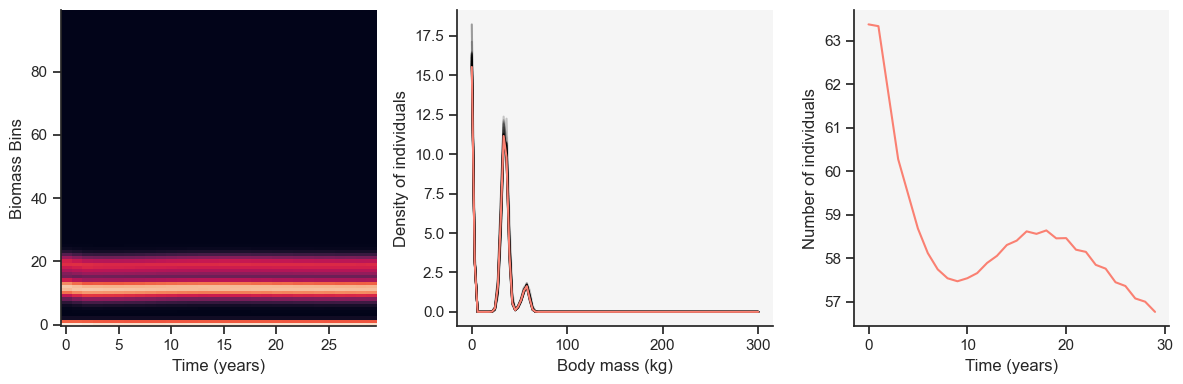

In [3]:
###############
## RUN MODEL ##
###############

## Initiate parameters
t_max = 29

## Period 1
t0 = time.time()
predictions = model.simulate(t_max=t_max,
                             Dt = Dt0,
                             Bt = Bt0,
                             Pt = Pt0,
                             Gt = Gt0,
                             NNt = NNt0,
                             NNNzt = NNNzt0,
                             zzmax = zzmax,
                             zzz_len = zzz_len
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions
tf = time.time()
print(f"{tf-t0:.2f}s")

## Visualise
plot_model(predictions)

#
###

In [4]:
#################################
## LOAD TIME SERIES AND FORMAT ##
#################################

import pandas as pd
import torch

## Load the dataset
df = pd.read_csv("A1-outputs/A1-tab-all-time-series.csv")

## Drop non-numeric/time columns
time_series_df = df.drop(columns=['time_step', 'year'])

## Convert to numeric
time_series_df = time_series_df.apply(pd.to_numeric, errors='coerce').astype('float64')

## Convert DataFrame to a NumPy array preserving missing values as np.nan
time_series_np = time_series_df.to_numpy()

## Convert to torch tensor with float64 precision
time_series_tensor = torch.tensor(time_series_np, dtype=torch.float64)[:,3:7]

print(time_series_tensor.shape) # Should be (num_timesteps, num_variables)

#
###

torch.Size([30, 4])


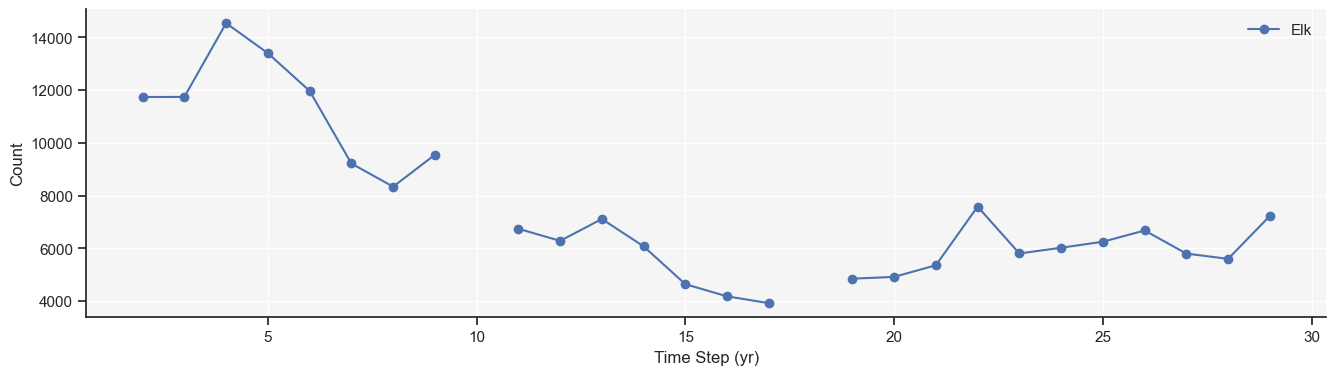

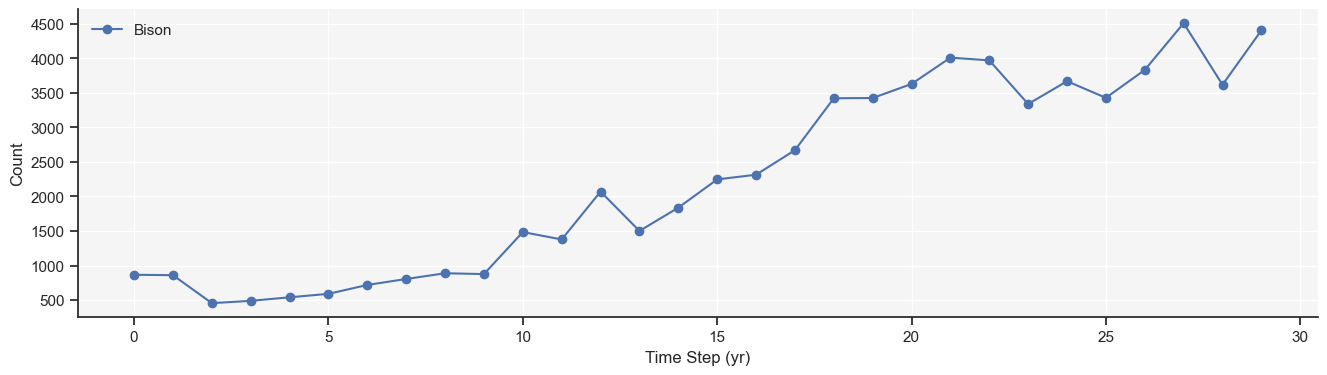

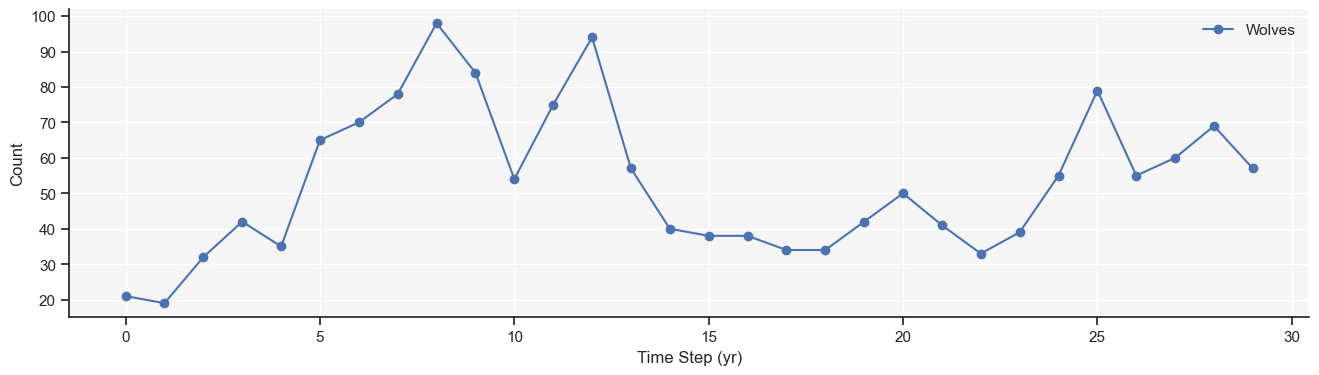

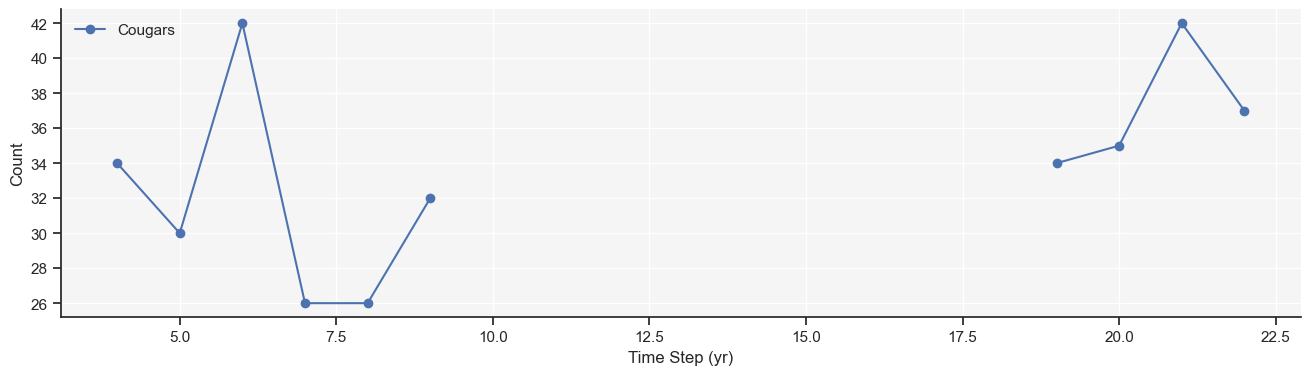

In [5]:
###################
## VISUALISATION ##
###################

def plot_time_series(time_series_tensor_):
    """    
    """     
    llabels = ['Elk', 'Bison', 'Wolves', 'Cougars']
    k = 0
    for i in range(4):        
        plt.figure(figsize=(16,4))
        plt.plot(time_series_tensor_[:, i], 'o-', label=llabels[k])
        plt.xlabel('Time Step (yr)')
        plt.ylabel('Count')
        plt.legend(frameon=False)
        plt.grid(color='white')        
        plt.show()
        plt.close()
        k += 1

## Plot
plot_time_series(time_series_tensor)

#
###

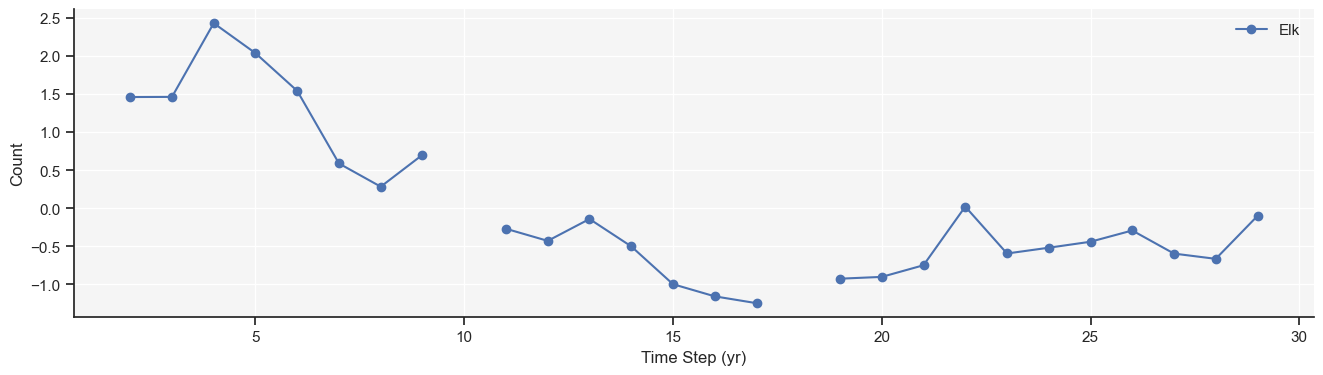

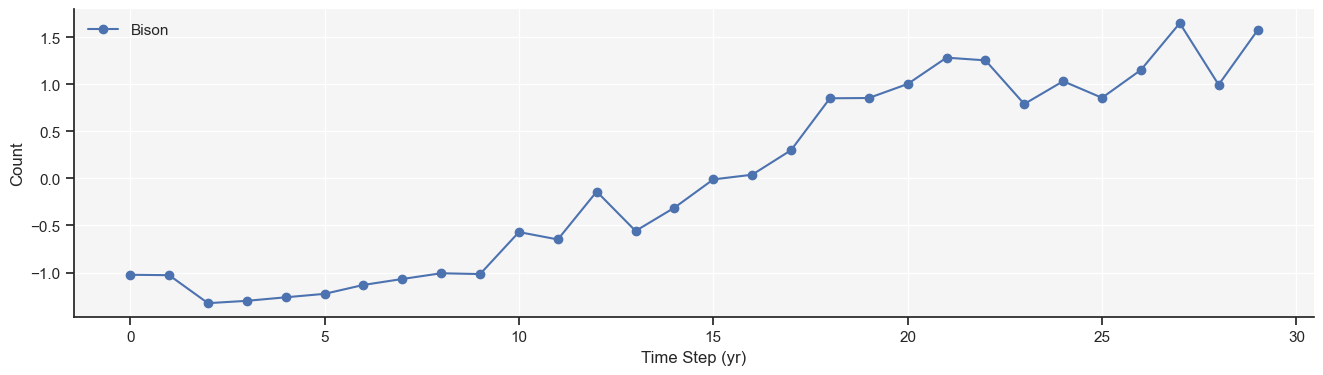

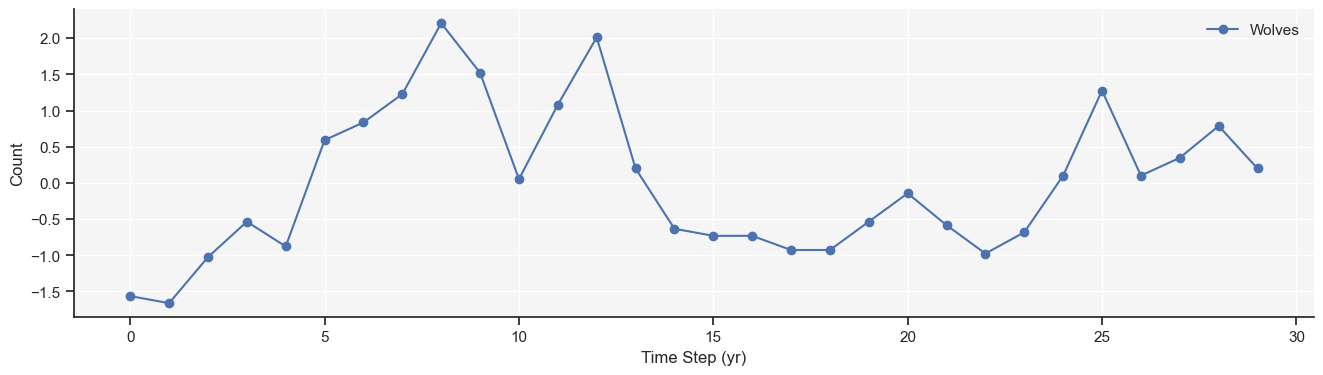

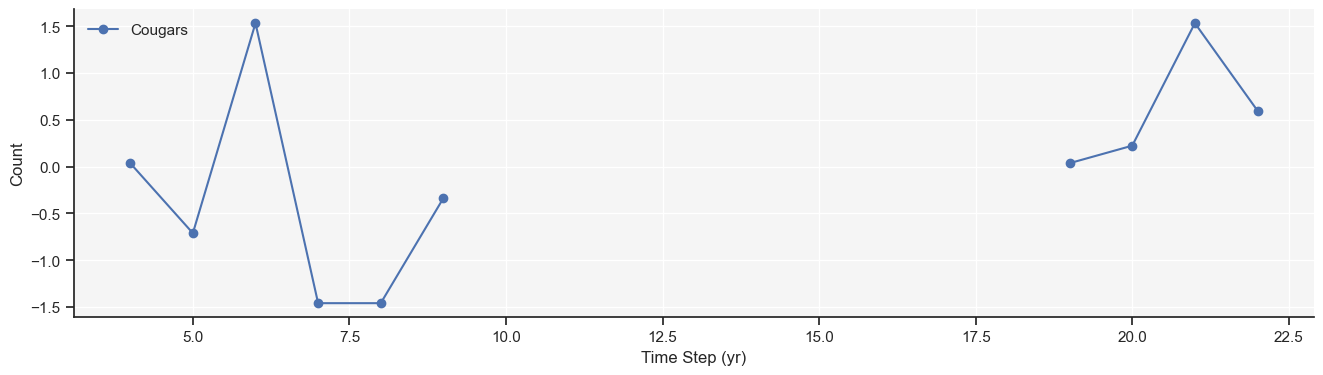

In [6]:
#####################
## STANDARDISATION ##
#####################

def compute_nan_mean_std(x, dim=None, keepdim=False, eps=1e-8):
    mask = ~torch.isnan(x)
    count = mask.sum(dim=dim, keepdim=True)

    x_masked = torch.where(mask, x, torch.tensor(0.0, dtype=x.dtype, device=x.device))
    mean = x_masked.sum(dim=dim, keepdim=True) / count

    var = ((torch.where(mask, x - mean, torch.tensor(0.0, dtype=x.dtype, device=x.device))) ** 2).sum(dim=dim, keepdim=True) / count
    std = torch.sqrt(var + eps)

    if not keepdim and dim is not None:
        mean = mean.squeeze(dim)
        std = std.squeeze(dim)

    return mean, std

def apply_standardization(x, mean, std):
    z = (x - mean) / std
    z = torch.where(torch.isnan(x), x, z)  # Preserve original NaNs
    return z

def reverse_standardization(z, mean, std):
    x = z * std + mean
    x = torch.where(torch.isnan(z), z, x)  # Preserve original NaNs
    return x

MEAN, STD = compute_nan_mean_std(time_series_tensor, 0)
time_series_tensor_standardised = apply_standardization(time_series_tensor, MEAN, STD)

## Check
plot_time_series(time_series_tensor_standardised)
# plt.plot(time_series_tensor_standardised)
# plt.yscale('log')
# plt.show()

#
###

In [7]:
########################
## FORMAT PREDICTIONS ##
########################

def format_predicted_time_series(predictions):
    zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions        
    time_series_tensor_predicted = NNNt[:,2:6]
    return time_series_tensor_predicted

## Check
time_series_tensor_predicted = format_predicted_time_series(predictions)
print(time_series_tensor_predicted.shape)

#
###

torch.Size([30, 4])


In [8]:
####################
## SIMULATED DATA ##
####################

## For debugging
# time_series_tensor = time_series_tensor_predicted.clone()

#
###

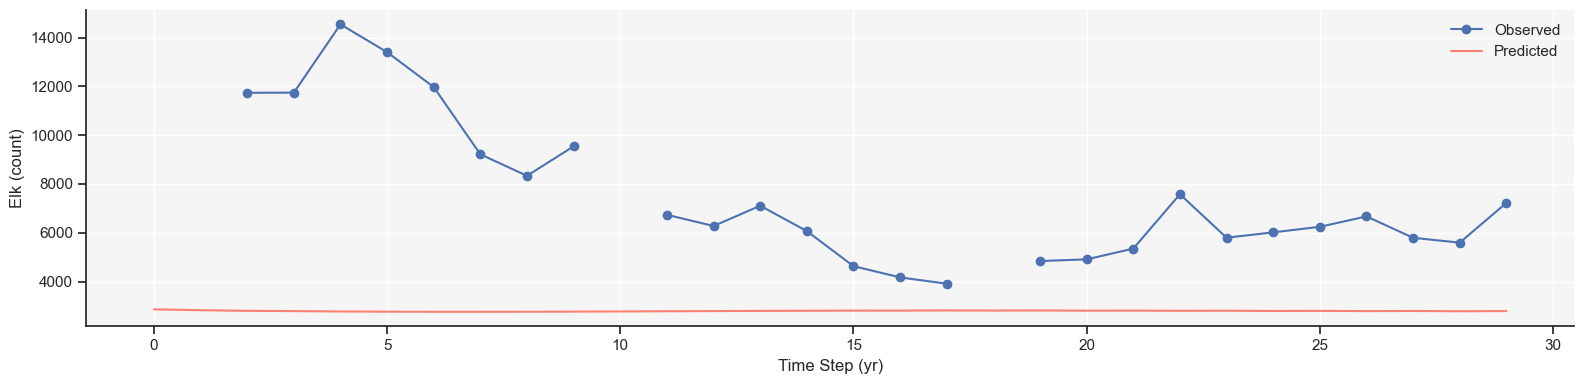

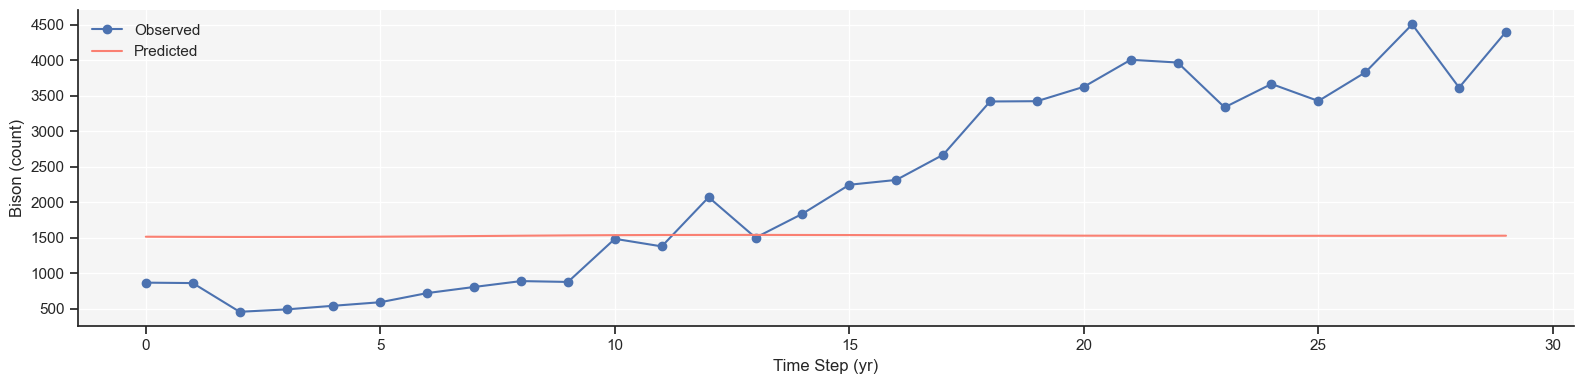

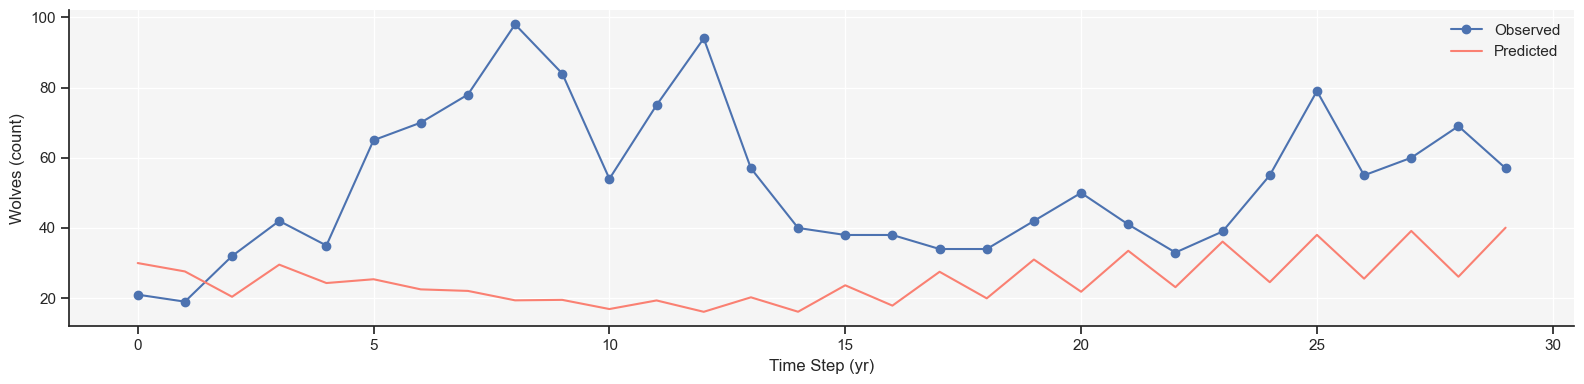

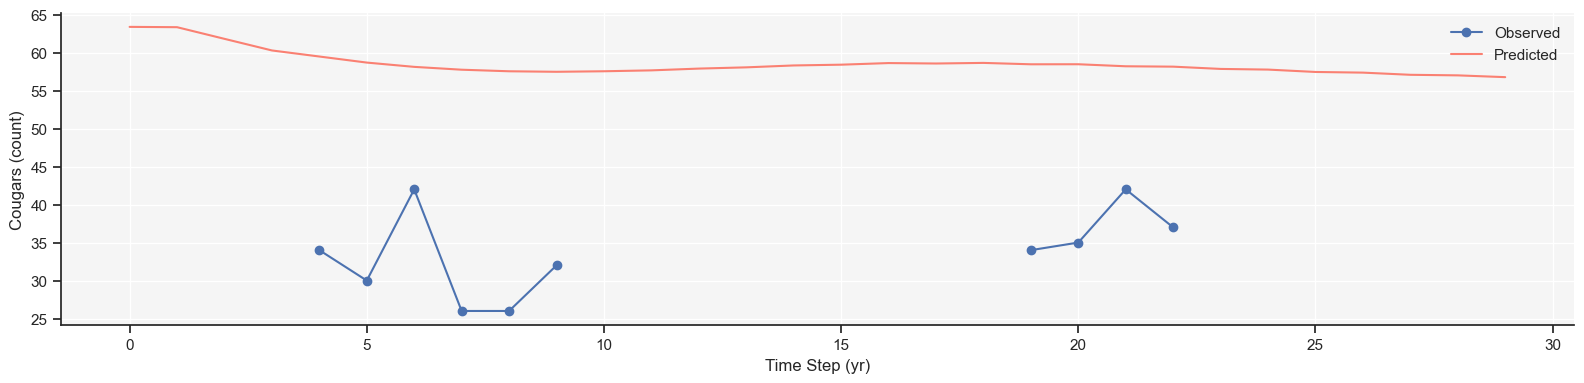

In [9]:
###################
## VISUALISATION ##
###################

def plot_fit_subplots(time_series_tensor, time_series_tensor_predicted, log=True):
    """    
    """     
    ccolors = ['brown', 'orange', 'grey', 'saddlebrown']
    yylabels = ['Elk (count)', 'Bison (count)', 'Wolves (count)', 'Cougars (count)']
    T, V = time_series_tensor.shape
    x = range(T)    
    for i in range(4):        
        plt.figure(figsize=(16,4))
        plt.plot(time_series_tensor[:, i], 'o-', label='Observed')
        plt.plot(x, time_series_tensor_predicted[:, i], '-', label='Predicted', color='salmon')
        plt.xlabel('Time Step (yr)')
        plt.ylabel(yylabels[i])
        plt.legend(frameon=False)
        plt.grid(color='white')        
        plt.tight_layout()
        plt.show()
        plt.close()        

## Check function
plot_fit_subplots(time_series_tensor, time_series_tensor_predicted)
    
#
###

torch.Size([6])
torch.Size([6])
torch.Size([6, 100])
0.26s


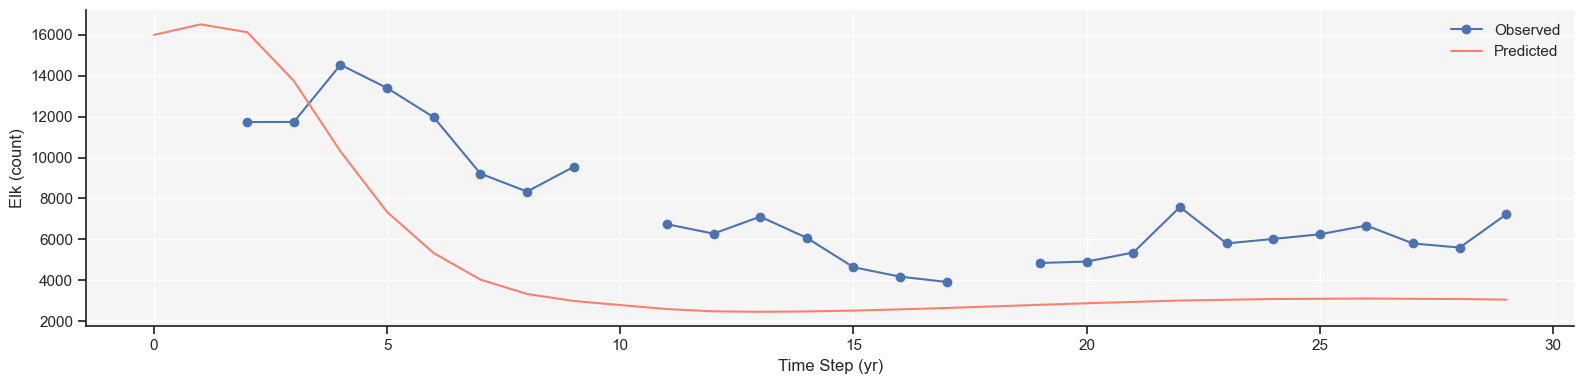

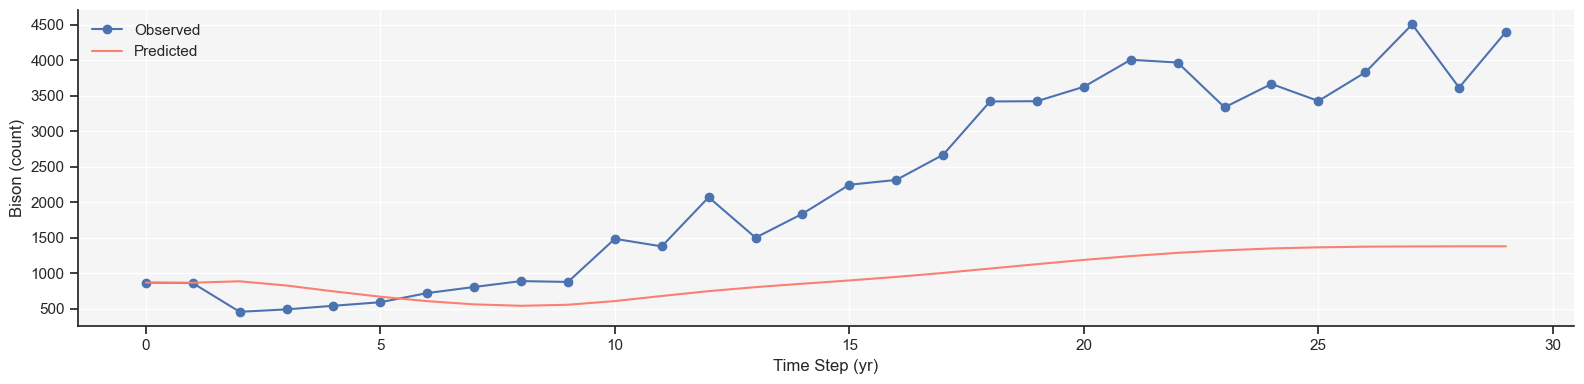

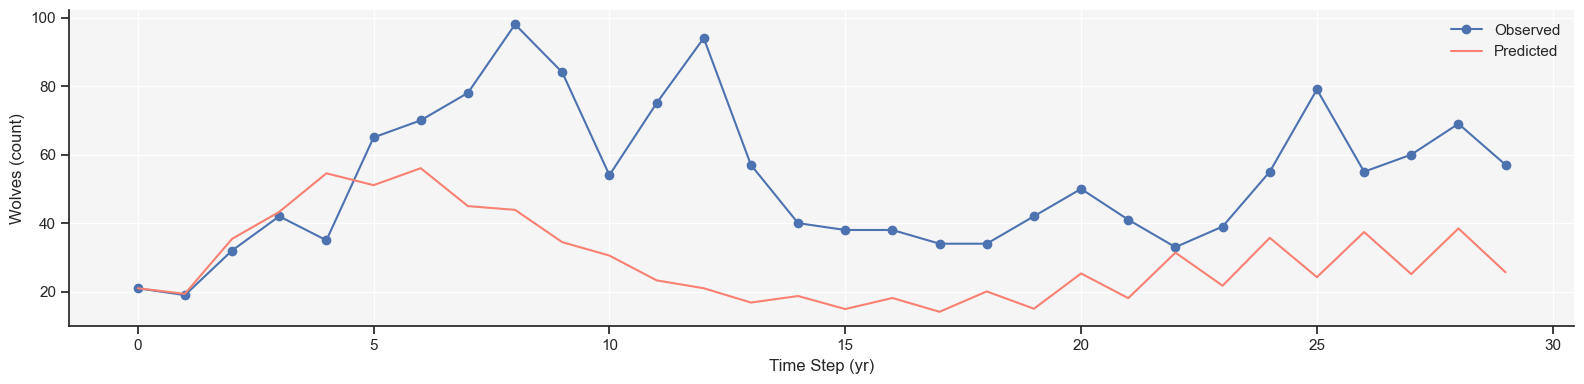

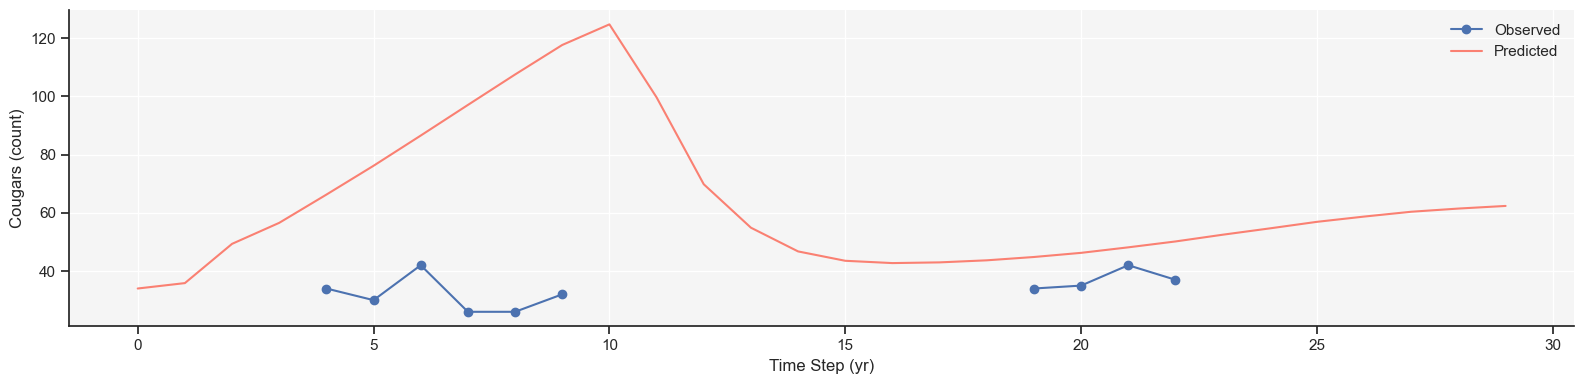

In [10]:
#####################################
## FIND SCALING INITIAL CONDITIONS ##
#####################################

SCALING = [] 
SCALING += [1.0] 
SCALING += [1.0] 
SCALING += [16000/time_series_tensor_predicted[0][0]]
SCALING += [time_series_tensor[0][1]/time_series_tensor_predicted[0][1]]
SCALING += [time_series_tensor[0][2]/time_series_tensor_predicted[0][2]]
SCALING += [time_series_tensor[4][3]/time_series_tensor_predicted[0][3]]
SCALING = torch.tensor(SCALING)
print(SCALING.shape)
print(NNt0.shape)
print(NNNzt0.shape)

## Run
t0 = time.time()
predictions = model.simulate(t_max=t_max,
                             Dt = Dt0,
                             Bt = Bt0,
                             Pt = Pt0,
                             Gt = Gt0,
                             NNt = NNt0 * SCALING,
                             NNNzt = NNNzt0 * SCALING[:,None],
                             zzmax = zzmax,
                             zzz_len = zzz_len
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions
tf = time.time()
print(f"{tf-t0:.2f}s")

## Check function
plot_fit_subplots(time_series_tensor, format_predicted_time_series(predictions))

#
###

In [11]:
####################################
## SET SCALING INITIAL CONDITIONS ##
####################################

## Initial conditions structured states
print(NNt0)
for i in range(len(NNt0)):
        NNt0[i] = NNt0[i] * SCALING[i]
        NNNzt0[i] = NNNzt0[i] * SCALING[i]
print(NNt0)

#
###

tensor([2.8845e+07, 5.3315e+07, 2.8643e+03, 1.5134e+03, 3.0000e+01, 6.3375e+01],
       dtype=torch.float64)
tensor([2.8845e+07, 5.3315e+07, 1.6000e+04, 8.6600e+02, 2.1000e+01, 3.4000e+01],
       dtype=torch.float64)


In [12]:
############################
## LOAD AND APPLY WRAPPER ##
############################

## Note: global variables should be in capital letters

## Import module
from f_wrapper_YEM_V1_14_2025_10_10 import wrapper_YEM_V1_14
from f_wrapper_YEM_V1_14_2025_10_10 import build_ttheta_index_map, get_name_from_index, get_index_from_name

## Model
model_r = YellowstoneEcosystemModel("parameters-apriori-V1-14-2025-10-10.yaml")
model_p = YellowstoneEcosystemModel("parameters-apriori-V1-14-2025-10-10.yaml")

## Define local wrapper
def wrapper(ttheta, t_max=29):
    return wrapper_YEM_V1_14(ttheta, t_max=t_max, model_r=model_r, model_p=model_p, Dt0=Dt0, Bt0=Bt0, Pt0=Pt0, Gt0=Gt0, NNt0=NNt0, NNNzt0=NNNzt0, zzmax=zzmax, zzz_len=zzz_len)

#
###

125


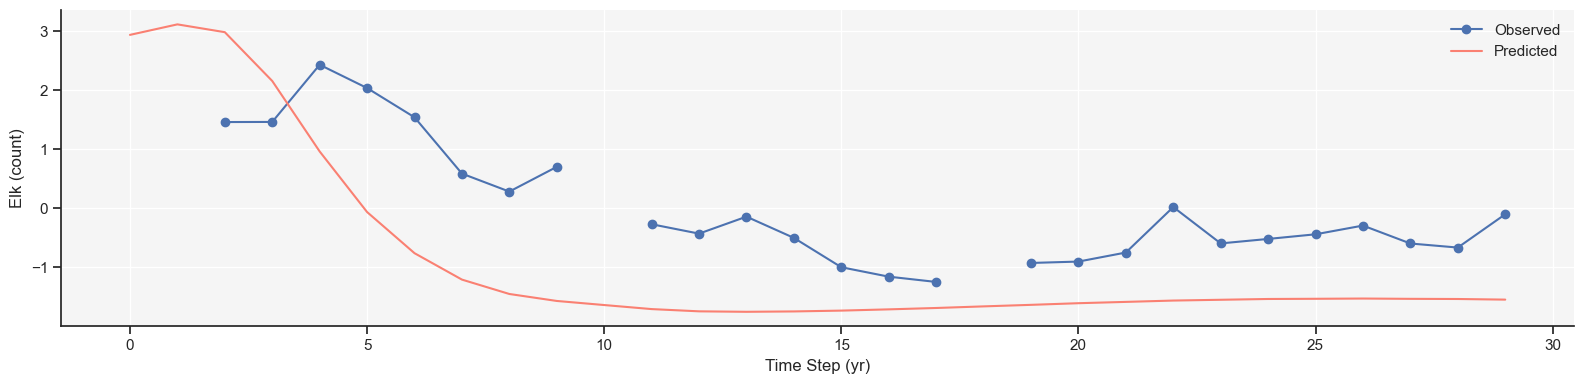

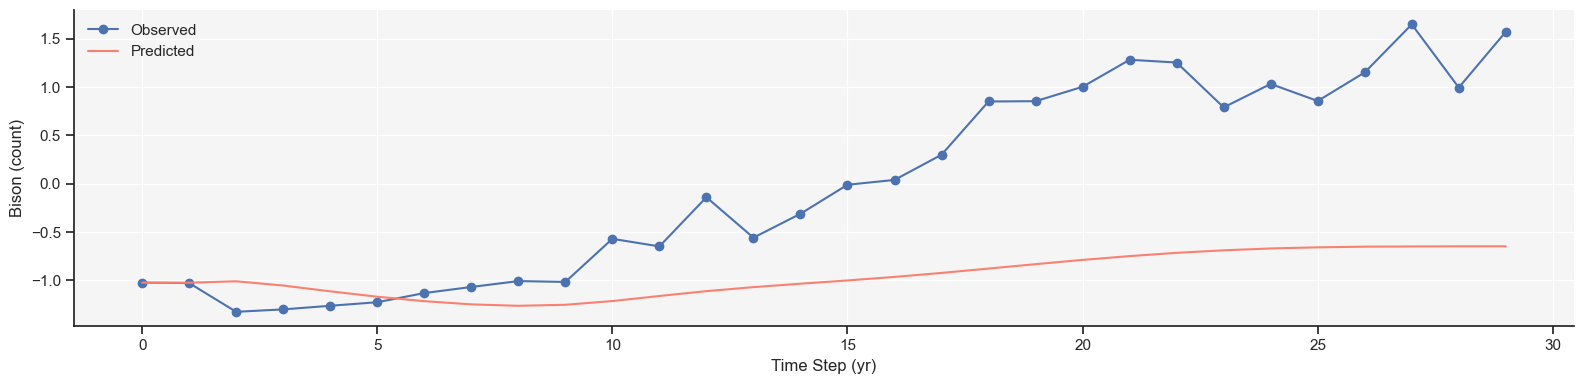

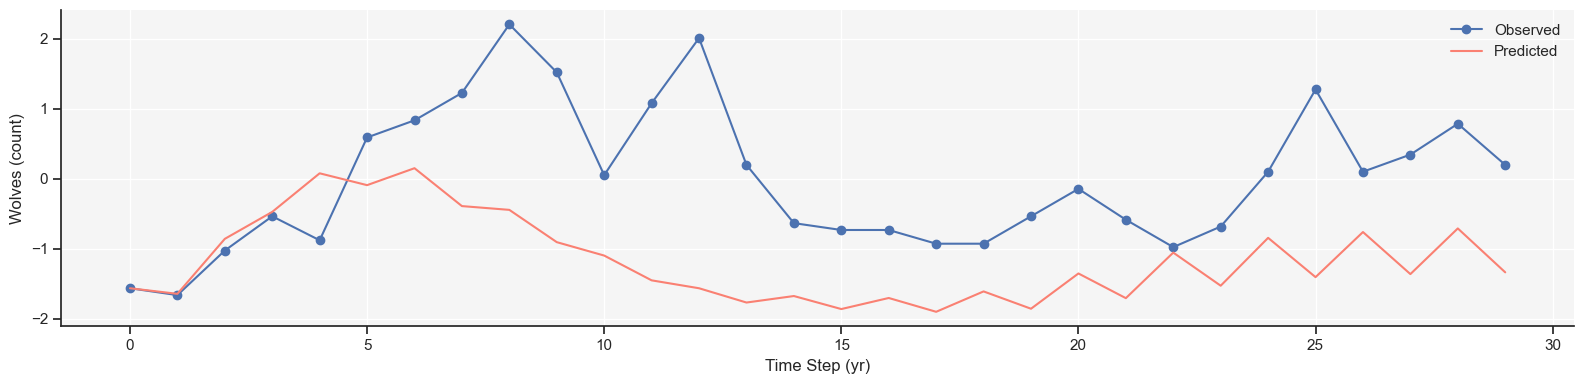

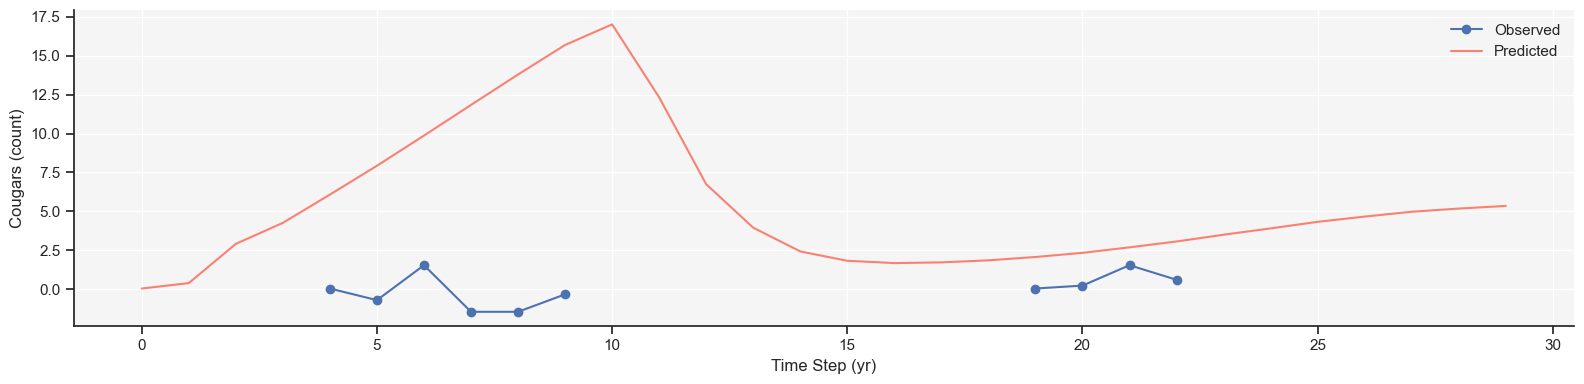

In [13]:
##################
## TEST WRAPPER ##
##################

## Scale parameter vector
num_parameters = len(build_ttheta_index_map(I=6, J=6))
print(num_parameters)
ttheta = torch.ones(num_parameters, dtype=torch.float64)

## Predict
predictions = wrapper(ttheta)
time_series_tensor_predicted = format_predicted_time_series(predictions)

## Standardise
time_series_tensor_predicted_standardised = apply_standardization(format_predicted_time_series(predictions), MEAN, STD)
time_series_tensor_standardised = apply_standardization(time_series_tensor, MEAN, STD)

## Visualise
plot_fit_subplots(time_series_tensor_standardised, time_series_tensor_predicted_standardised, log=False)

#
###

In [14]:
############################
## POSTERIOR DISTRIBUTION ##
############################

## Laplace priors
def log_prior(ttheta, sigma):
    return -1.0/sigma * torch.sum(torch.abs(ttheta - 1.0))

## Gaussian likelihood
def log_likelihood(ttheta):

    ## Predict
    predictions = wrapper(ttheta)
    
    ## Format
    time_series_tensor_predicted = format_predicted_time_series(predictions)

    ## Check for nans
    if torch.sum(torch.isnan(time_series_tensor_predicted))>1:
        log_lik = -float('inf')        
    else:      
        ## Standardise
        time_series_tensor_predicted_standardised = apply_standardization(format_predicted_time_series(predictions), MEAN, STD)            
        
        ## Compute residuals
        res = time_series_tensor_predicted_standardised - time_series_tensor_standardised

        ## Mean of mean squares for each time series            
        log_lik = torch.tensor(0.0, dtype=torch.float64)
        for i in range(res.shape[1]):
            log_lik += - torch.nanmean(res[:,i]**2)

    ## End
    return log_lik

def log_posterior(ttheta, sigma=0.2):
    log_lik = log_likelihood(ttheta)
    log_pri = log_prior(ttheta, sigma)
    log_pos = log_lik + log_pri
    return log_pos, log_lik, log_pri

SIGMA = 1.0
def d_target(ttheta):        
    log_pos, _, _ = log_posterior(ttheta, sigma=SIGMA)
    return log_pos
    
#
###

In [15]:
############
## CHECKS ##
############

## Check priors
ttheta_0 = torch.ones(num_parameters, dtype=torch.float64)
print(log_prior(ttheta_0, .2))

## Check posterior
t0 = time.time()
ttheta_0 = torch.ones(num_parameters, dtype=torch.float64)
print(log_posterior(ttheta_0))
tf = time.time()
print(f"time: {tf-t0:2f}s")
    
#
###

tensor(-0., dtype=torch.float64)
(tensor(-91.9208, dtype=torch.float64), tensor(-91.9208, dtype=torch.float64), tensor(-0., dtype=torch.float64))
time: 0.258851s


In [16]:
#########################################
## FUNCTIONS ANALYSIS OF CHAIN RESULTS ##
#########################################

def get_map(chain):
    idx = torch.argmax(chain[:,0])
    ttheta_map = chain[idx,1:]
    return ttheta_map

def plot_chain(chain):
    """
    """
    ## Trace plots
    plt.figure()
    plt.plot(chain[:, 0])
    # plt.title("Trace plot: theta[0]")
    plt.xlabel("Iteration")
    plt.ylabel("Value")
    plt.show()
    
    plt.figure()
    plt.plot(chain[:, 1])
    # plt.title("Trace plot: theta[0]")
    plt.xlabel("Iteration")
    plt.ylabel("Value")
    plt.show()
    
    plt.figure()
    plt.plot(chain[:, 2])
    # plt.title("Trace plot: theta[1]")
    plt.xlabel("Iteration")
    plt.ylabel("Value")
    plt.show()
    
    # Scatter plot
    plt.figure()
    plt.plot(chain[:, 1], chain[:, 2])
    # plt.scatter(samples[:, 0], samples[:, 1], alpha=0.3, s=1)
    # plt.title("Posterior samples")
    plt.xlabel("theta[0]")
    plt.ylabel("theta[1]")
    # plt.axis("equal")
    plt.show()
    
    plt.figure()
    plt.plot(chain[:,1:11], alpha=0.2)
    plt.show()
       
#
###

In [ ]:
###############
## RUN CHAIN ##
###############

## WARNING: 
## Only run for inference due to long fitting times (~1–2 hours per optimisation run).
## Change variable RUN (see below) to True to run the optimisation

## Import module
from f_demc_sparse_noise import de_mcmc_single_chain_sparse_optimiser

## Initiate
PTOF = "C4-outputs/"
if os.path.exists(PTOF) == False: 
    os.mkdir(PTOF)
DATE = '2026-08-10'
RUN_ID = f"C4-real-map-sigma-{SIGMA}-{DATE}"
RUN = False 

## Run
if RUN:
    
    ## Multiple runs
    num_runs = 30
    for k in range(10, num_runs):
    #
    ## Selected runs
    # for k in [1]:
    
        print('')
        print(f"{RUN_ID}-{k+1}")    
        
        ## Select initial value
        d_target_ = -torch.inf
        while d_target_ == -torch.inf:
            ttheta_map = ttheta_0 = torch.ones(num_parameters, dtype=torch.float64) + torch.rand(ttheta.shape) * 1e-3
            d_target_ = d_target(ttheta_0)
            print(d_target_)    
        
        ## Initiate run
        num_epoch = 1000
        stop_counter = 0
        max_stop_count = 3
        lloss = [log_posterior(ttheta_map, sigma=SIGMA)]
        cchain = []
        for epoch in range(num_epoch):
    
            ## Iterator
            print('')
            print(f"epoch {epoch+1}/{num_epoch}")
            
            ## Step
            t0 = time.time()
            results = de_mcmc_single_chain_sparse_optimiser(
                d_target=d_target,
                theta_0=ttheta_map,
                epsilon=0.0,
                p_sparse=0.5e-01,
                scale_sparse=1e-02,
                memory=25,
                n_it=100,
                verbose=True  # set True for intermediate output
            )
            tf = time.time()
            print(f"time: {tf-t0:2f}s")
            
            ## Extract chain
            chain = results['chain']
            cchain += [chain[-1]]
            
            ## Get MaP
            ttheta_map_new = get_map(chain)
            loss = log_posterior(ttheta_map_new, sigma=SIGMA)
            lloss += [log_posterior(ttheta_map_new, sigma=SIGMA)]
            print(loss)
            
            ## Update map
            if d_target(ttheta_map_new) > d_target(ttheta_map) + 1e-4:
                ttheta_map = ttheta_map_new.clone()
                stop_counter = 0 # reset stop counter
            else:
                stop_counter += 1
                if stop_counter >= max_stop_count:            
                    print(f"training ended after {epoch+1} epochs")
                    break        
                    
        ## Save
        torch.save(chain, f"{PTOF}{RUN_ID}-{k+1}-chain.pt")
        torch.save(cchain, f"{PTOF}{RUN_ID}-{k+1}-cchain.pt")
        torch.save(lloss, f"{PTOF}{RUN_ID}-{k+1}-lloss.pt")    
                    
#
###

In [17]:
#############################
## LOAD CHAIN OPTIMISATION ##
#############################

for k in range(0,10):    
    sigma = 1.0
    date = '2025-10-13'
    run_id = f"C4-outputs/C4-real-map-sigma-{sigma}-{date}"        
    chain = torch.load(f"{run_id}-{k+1}-chain.pt")
    cchain = torch.load(f"{run_id}-{k+1}-cchain.pt")
    lloss = torch.load(f"{run_id}-{k+1}-lloss.pt")
    ttheta_map = get_map(chain)
    print(log_posterior(ttheta_map, sigma=sigma))

for k in range(10,30):    
    sigma = 1.0
    date = '2026-08-10'
    run_id = f"C4-outputs/C4-real-map-sigma-{sigma}-{date}"        
    chain = torch.load(f"{run_id}-{k+1}-chain.pt")
    cchain = torch.load(f"{run_id}-{k+1}-cchain.pt")
    lloss = torch.load(f"{run_id}-{k+1}-lloss.pt")
    ttheta_map = get_map(chain)
    print(log_posterior(ttheta_map, sigma=sigma))

#
###

/var/folders/tb/4hh90ttd1nl4xf1zbfyq_n8w0000gp/T/ipykernel_73369/2995651277.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chain = torch.load(f"{run_id}-{k+1}-chain.pt"

(tensor(-4.4011, dtype=torch.float64), tensor(-2.0644, dtype=torch.float64), tensor(-2.3367, dtype=torch.float64))
(tensor(-10.2120, dtype=torch.float64), tensor(-5.2776, dtype=torch.float64), tensor(-4.9343, dtype=torch.float64))
(tensor(-4.2803, dtype=torch.float64), tensor(-1.8554, dtype=torch.float64), tensor(-2.4249, dtype=torch.float64))
(tensor(-7.6794, dtype=torch.float64), tensor(-4.7529, dtype=torch.float64), tensor(-2.9265, dtype=torch.float64))
(tensor(-4.7167, dtype=torch.float64), tensor(-2.0793, dtype=torch.float64), tensor(-2.6374, dtype=torch.float64))
(tensor(-4.1602, dtype=torch.float64), tensor(-1.8662, dtype=torch.float64), tensor(-2.2940, dtype=torch.float64))
(tensor(-4.2334, dtype=torch.float64), tensor(-1.7934, dtype=torch.float64), tensor(-2.4400, dtype=torch.float64))
(tensor(-8.5033, dtype=torch.float64), tensor(-4.5876, dtype=torch.float64), tensor(-3.9157, dtype=torch.float64))
(tensor(-10.5190, dtype=torch.float64), tensor(-2.8161, dtype=torch.float64), t

/var/folders/tb/4hh90ttd1nl4xf1zbfyq_n8w0000gp/T/ipykernel_73369/2995651277.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chain = torch.load(f"{run_id}-{k+1}-chain.pt

(tensor(-8.7592, dtype=torch.float64), tensor(-5.6113, dtype=torch.float64), tensor(-3.1479, dtype=torch.float64))
(tensor(-4.8888, dtype=torch.float64), tensor(-1.8838, dtype=torch.float64), tensor(-3.0050, dtype=torch.float64))
(tensor(-3.9321, dtype=torch.float64), tensor(-1.8413, dtype=torch.float64), tensor(-2.0908, dtype=torch.float64))
(tensor(-9.2270, dtype=torch.float64), tensor(-5.3232, dtype=torch.float64), tensor(-3.9038, dtype=torch.float64))
(tensor(-4.7827, dtype=torch.float64), tensor(-1.9986, dtype=torch.float64), tensor(-2.7841, dtype=torch.float64))
(tensor(-4.4101, dtype=torch.float64), tensor(-1.7942, dtype=torch.float64), tensor(-2.6159, dtype=torch.float64))
(tensor(-4.1320, dtype=torch.float64), tensor(-1.8294, dtype=torch.float64), tensor(-2.3025, dtype=torch.float64))
(tensor(-4.0047, dtype=torch.float64), tensor(-1.8364, dtype=torch.float64), tensor(-2.1683, dtype=torch.float64))
(tensor(-3.7649, dtype=torch.float64), tensor(-1.8722, dtype=torch.float64), ten

In [24]:
#####################
## LOAD SINGLE RUN ##
#####################

k = 18 # 1/3 best models
# k = 29 # 2/3 best models
# k = 27 # 2/3 best models
chain = torch.load(f"{run_id}-{k+1}-chain.pt")
cchain = torch.load(f"{run_id}-{k+1}-cchain.pt")
lloss = torch.load(f"{run_id}-{k+1}-lloss.pt")
ttheta_map = get_map(chain)
print(log_posterior(ttheta_map, sigma=sigma))

#
###

/var/folders/tb/4hh90ttd1nl4xf1zbfyq_n8w0000gp/T/ipykernel_73369/2759517411.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chain = torch.load(f"{run_id}-{k+1}-chain.pt"

(tensor(-3.7649, dtype=torch.float64), tensor(-1.8722, dtype=torch.float64), tensor(-1.8927, dtype=torch.float64))


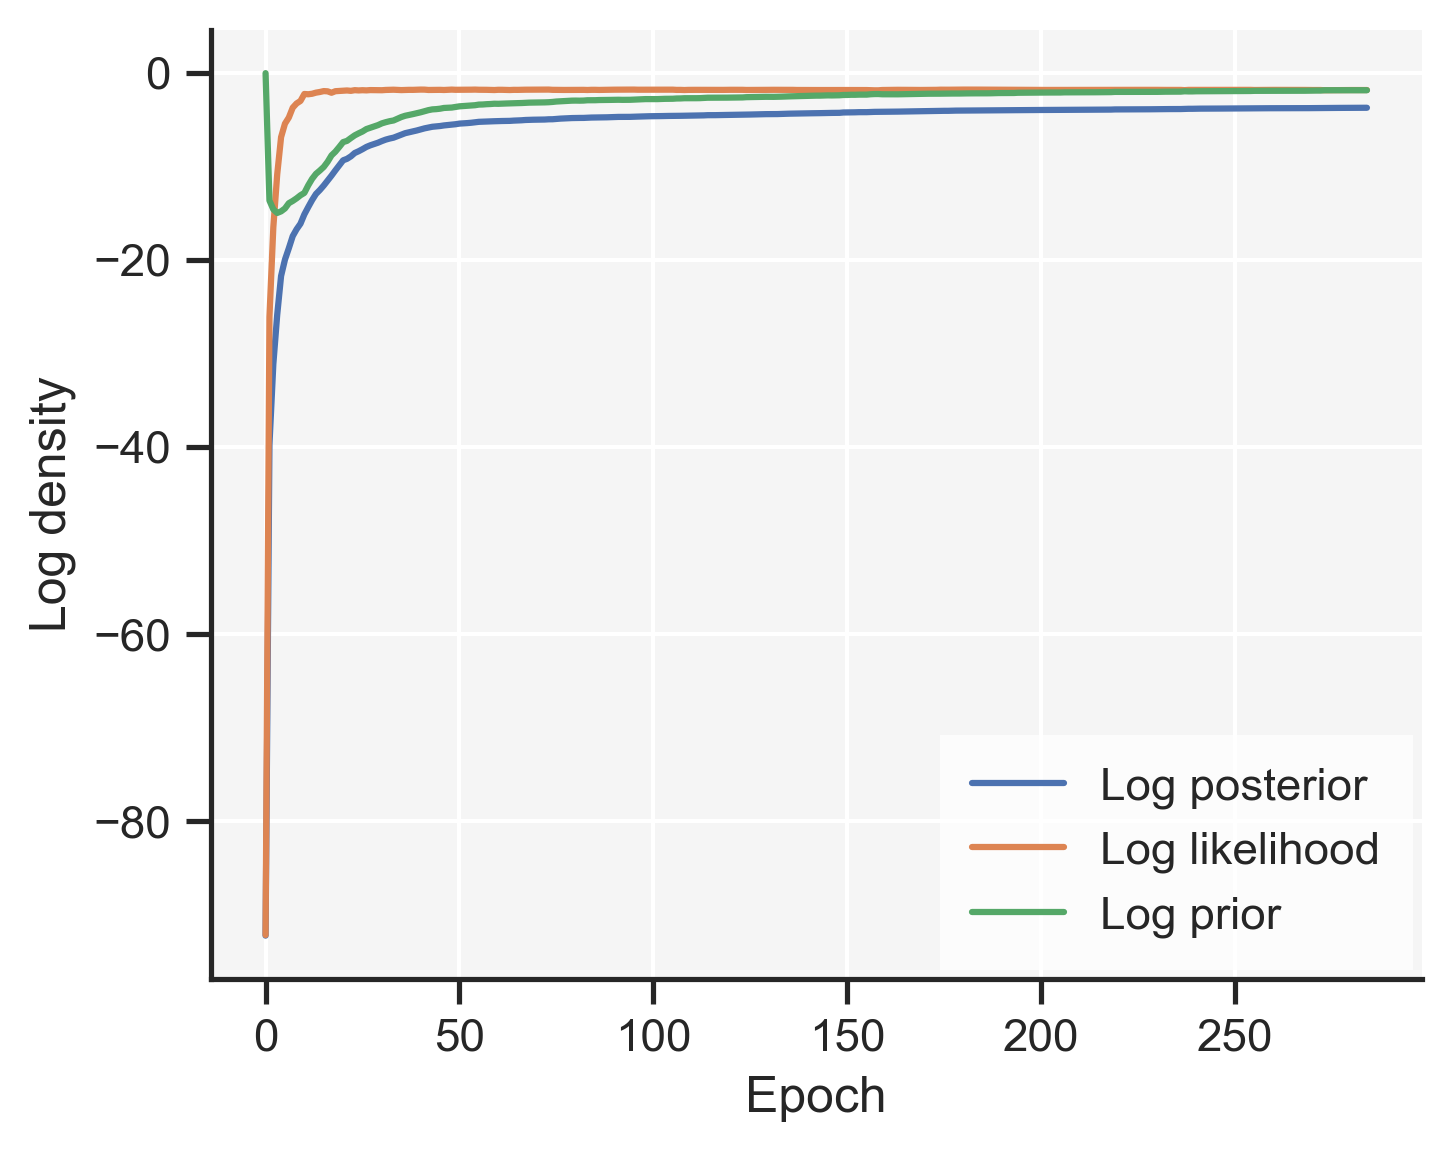

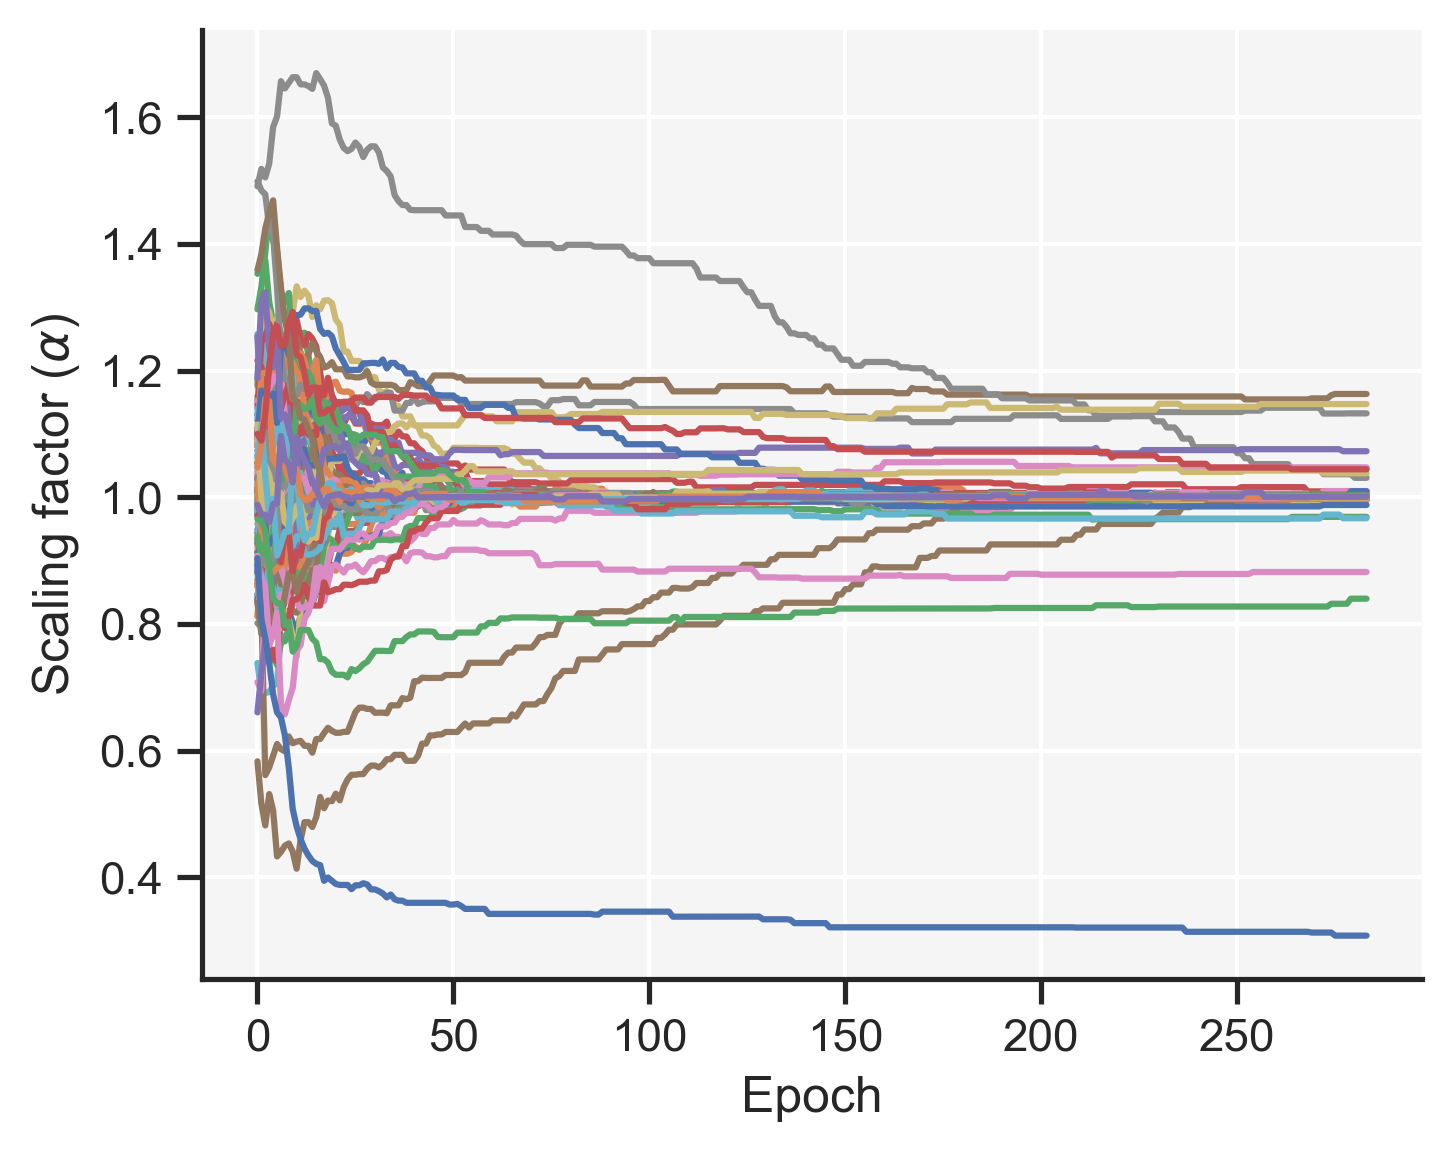

In [25]:
##################################
## VISUALISE CHAIN OPTIMISATION ##
##################################

## Global variables
FIGRES = 300
FIGSIZE = (5,4)
SAVE = SAVEFIGS

## Set res
plt.rcParams['figure.dpi'] = FIGRES

## Visualise posterior components
plt.figure(figsize=FIGSIZE)
plt.plot(np.stack(lloss)[:,0], label='Log posterior')
plt.plot(np.stack(lloss)[:,1], label='Log likelihood')
plt.plot(np.stack(lloss)[:,2], label='Log prior')
# plt.legend(frameon=False)
leg = plt.legend(loc='lower right', ncol=1, fontsize=11)
frame = leg.get_frame()
frame.set_boxstyle('square')
frame.set_facecolor('white')
frame.set_edgecolor('none')
plt.xlabel('Epoch')
plt.ylabel('Log density')
plt.grid(color='white')
# plt.title('a.', fontweight='bold', loc='right')
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-calibrated-full-data-posterior.pdf")
else:
    plt.show()
    plt.close()

## Visualise chain
plt.figure(figsize=FIGSIZE)
plt.plot(np.stack(cchain)[:,1:])
plt.xlabel('Epoch')
plt.ylabel(fr"Scaling factor ($\alpha$)")
plt.grid(color='white')
# plt.title('b.', fontweight='bold', loc='right')
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-calibrated-full-data-trace.pdf")
else:
    plt.show()
    plt.close()

## End
plt.rcParams['figure.dpi'] = 100

#
###

In [26]:
#############
## GET MAP ##
#############

## Plot fit
ttheta_map = get_map(chain)

#
###

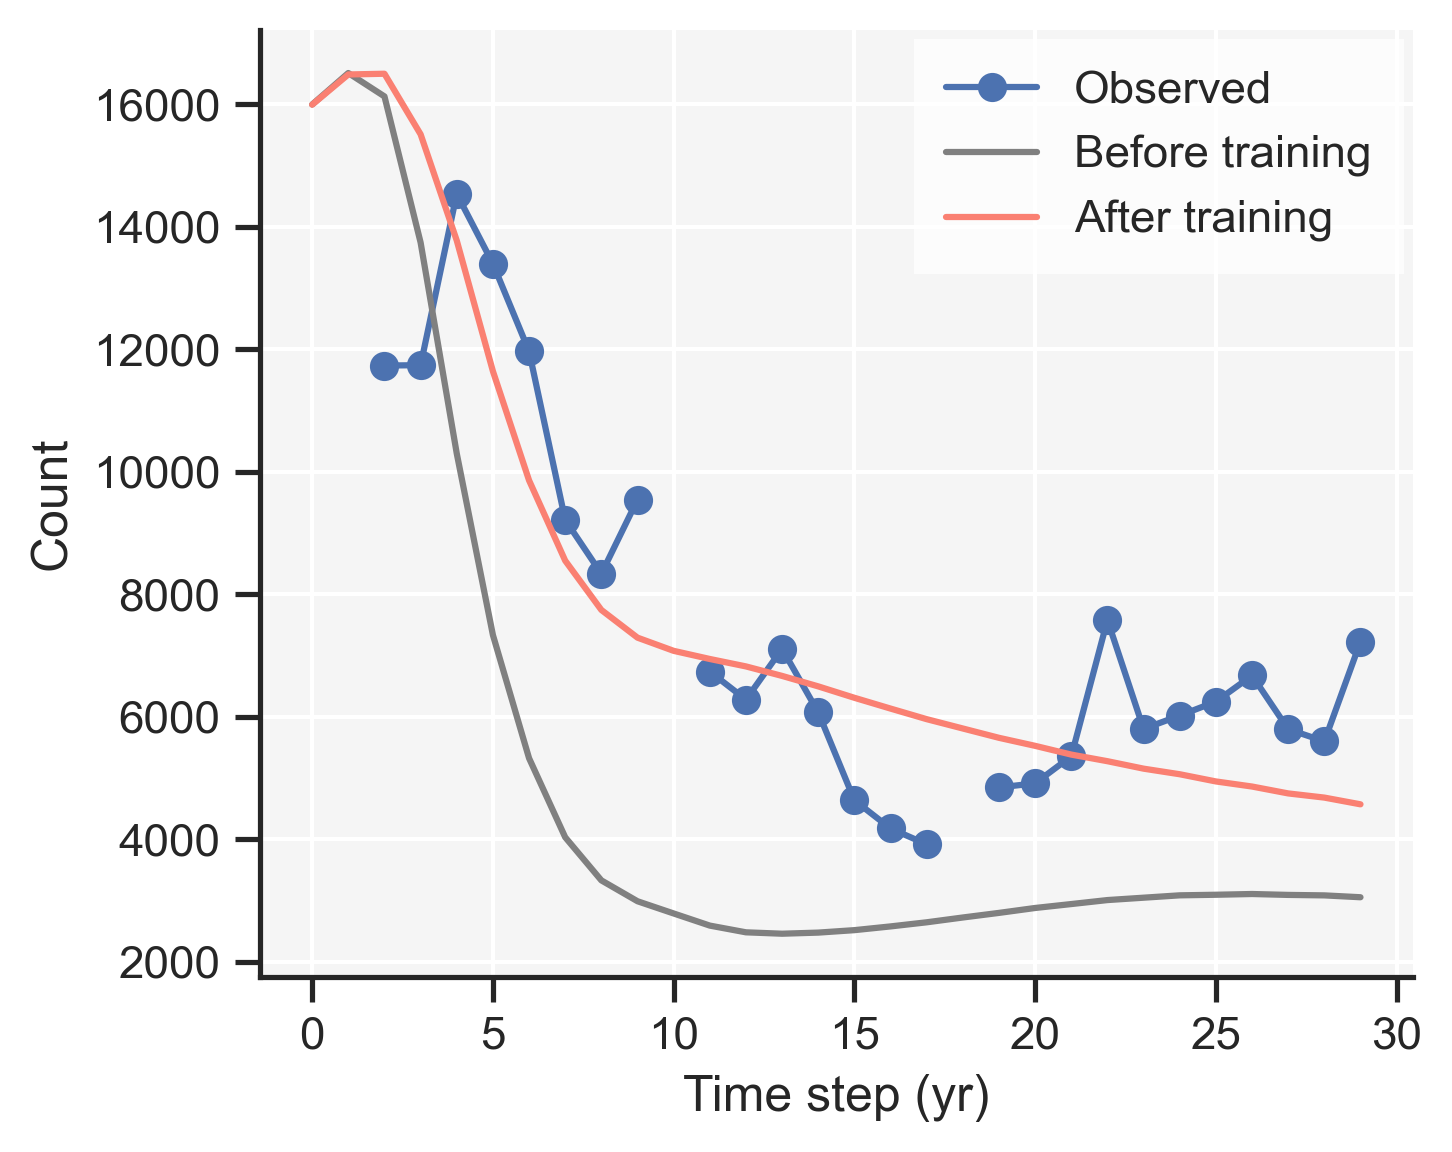

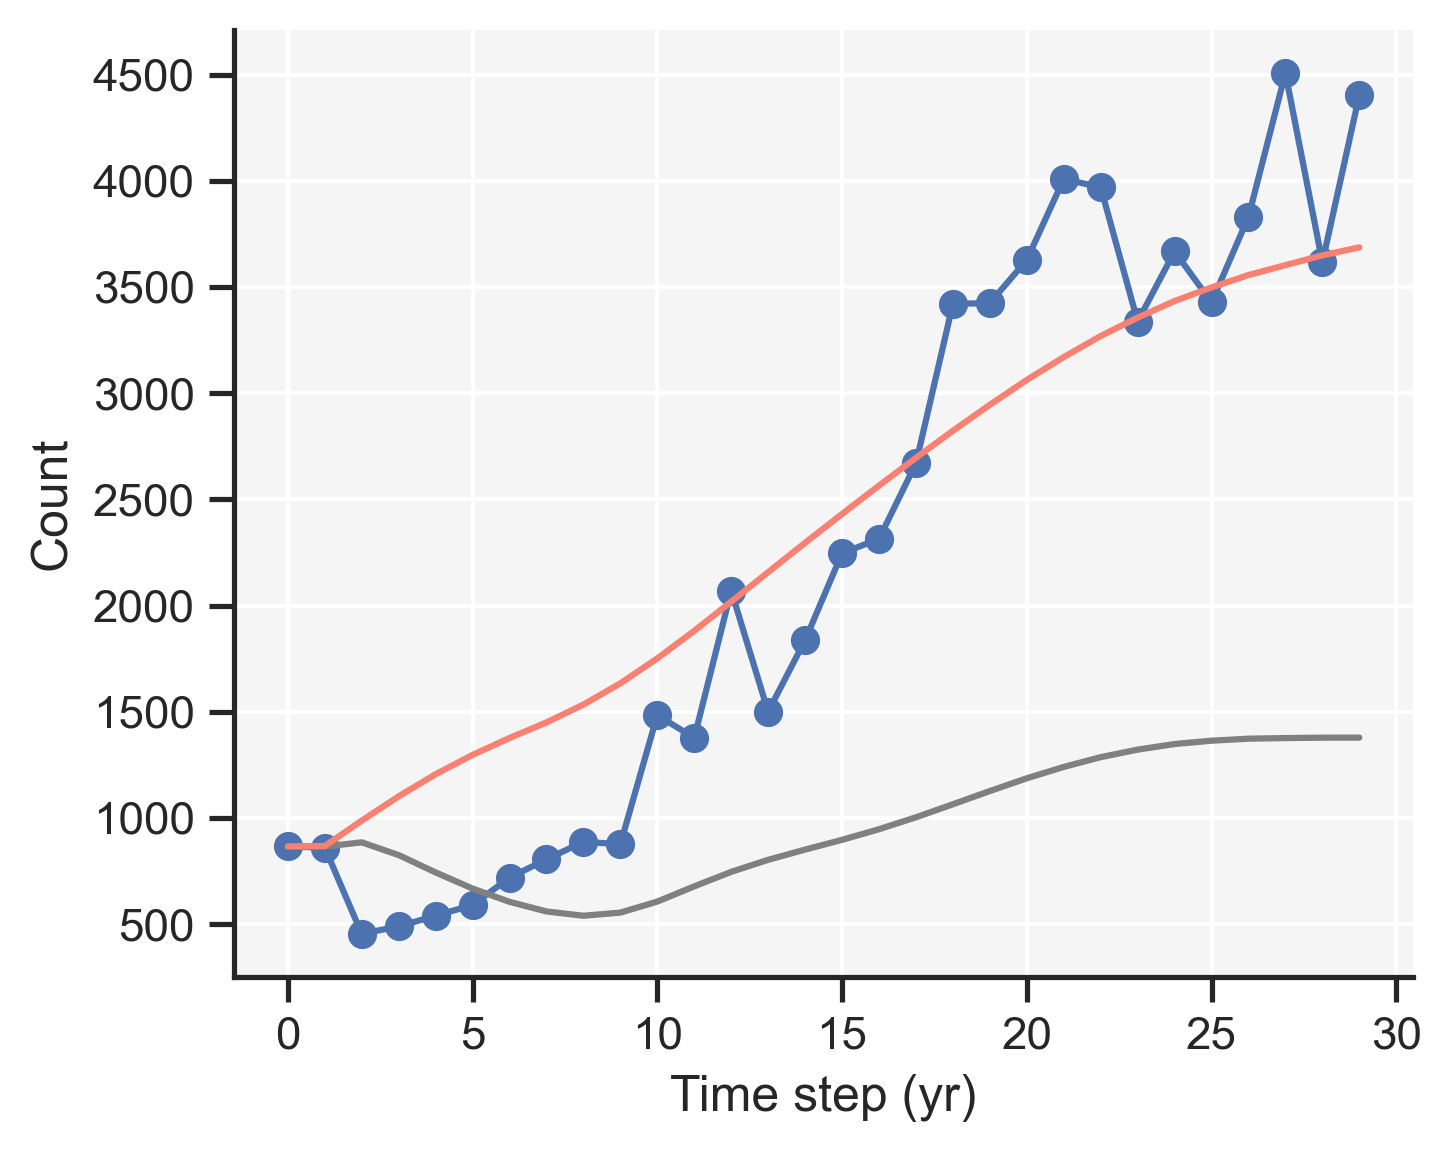

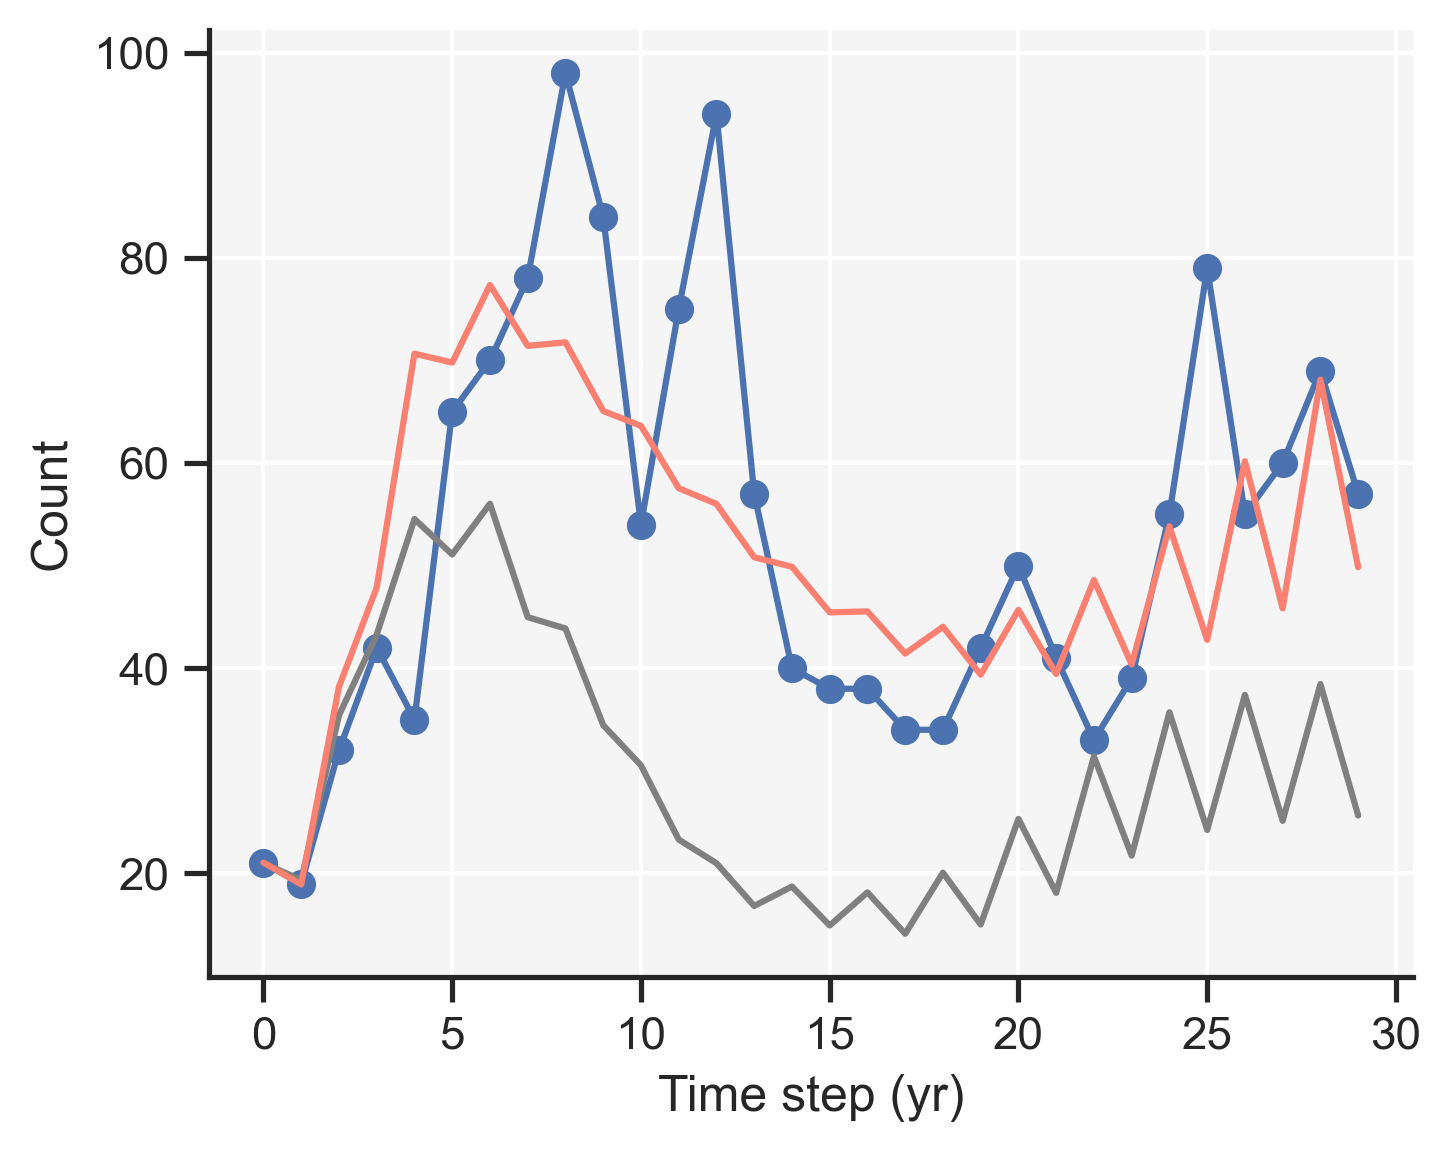

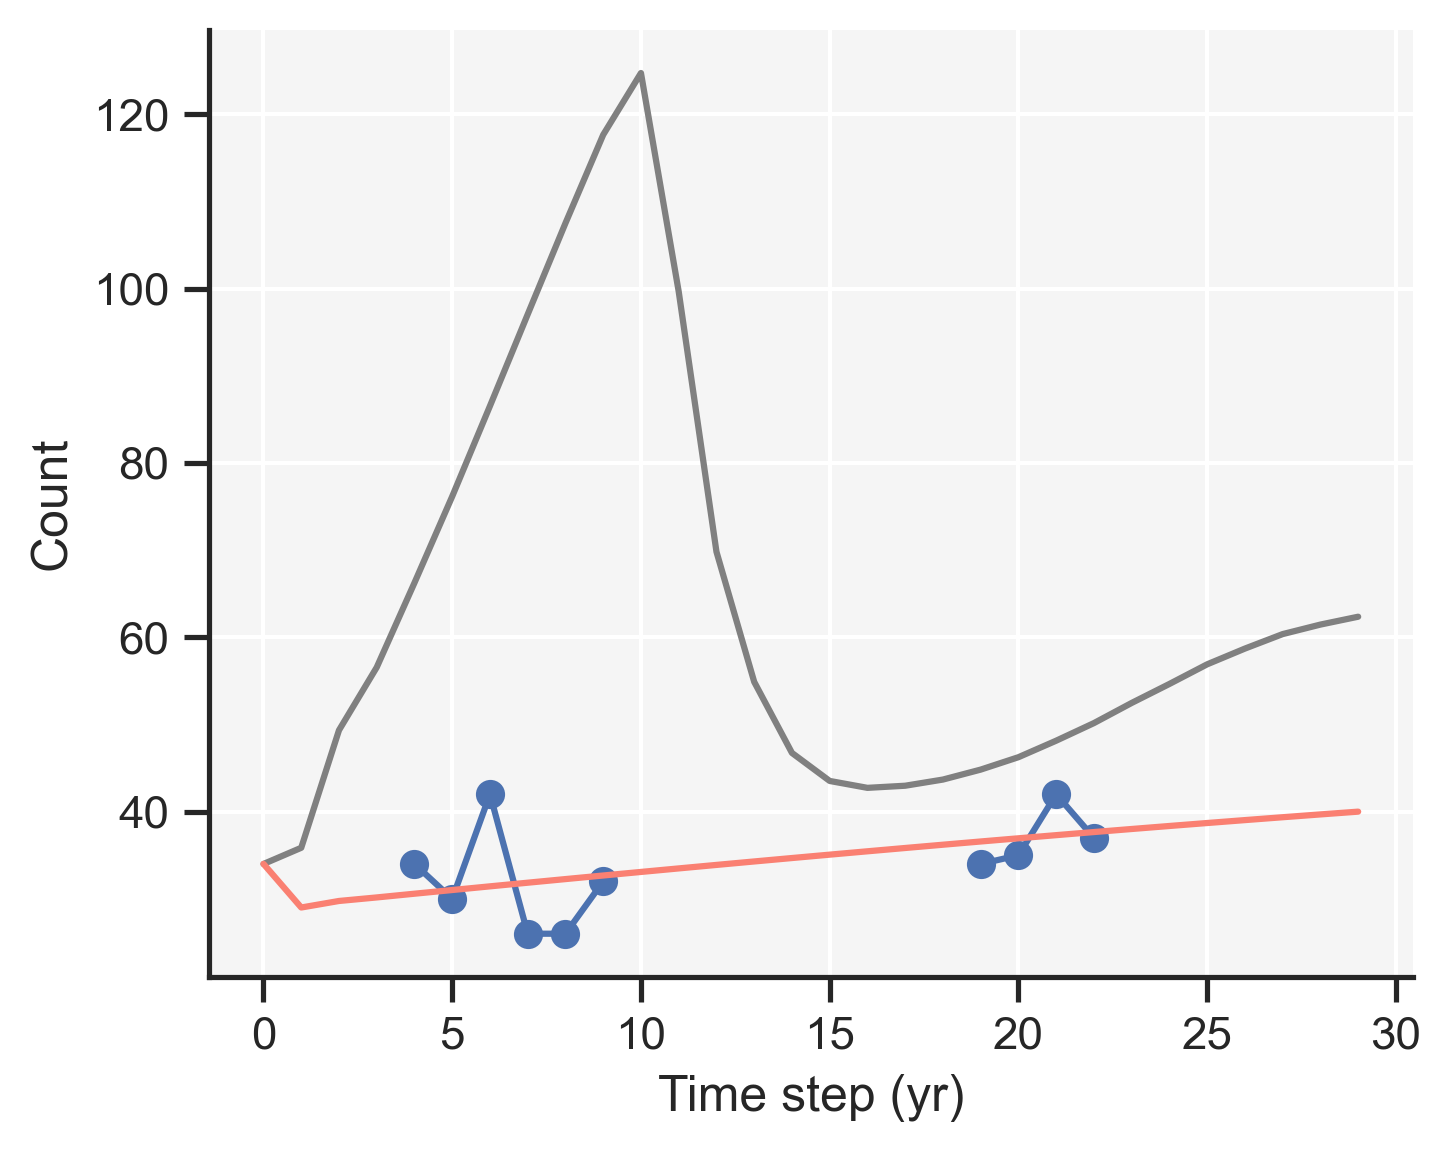

In [27]:
###########################
## VISUALISE FIT COMPACT ##
###########################

## Global variables
SAVE = SAVEFIGS
FIGSIZE = (5,4)
FIGRES = 300

## Initial parameter vector
ttheta_0 = torch.ones(num_parameters)

## Predict
predictions_0 = wrapper(ttheta_0)
predictions_map = wrapper(ttheta_map)

## Format and standardize
pred_0 = format_predicted_time_series(predictions_0)
# pred_0 = apply_standardization(format_predicted_time_series(predictions_0), MEAN, STD)
pred_map = format_predicted_time_series(predictions_map)
# pred_map = apply_standardization(format_predicted_time_series(predictions_map), MEAN, STD)
true = time_series_tensor

## Figure
plt.rcParams['figure.dpi'] = FIGRES
llabels = ['a.', 'b.', 'c.', 'd.']
k = 0
for i in [0, 1, 2, 3]:
    plt.figure(figsize=FIGSIZE)    
    plt.plot(true[:, i], 'o-', label='Observed')
    plt.plot(pred_0[:, i], label='Before training', color='grey')
    plt.plot(pred_map[:, i], label='After training', color='salmon')
    plt.xlabel('Time step (yr)')
    plt.ylabel('Count')    
    # plt.legend(frameon=False, fontsize=11)
    if i == 0:
        leg = plt.legend(loc='upper right', ncol=1, fontsize=11)
        frame = leg.get_frame()
        frame.set_boxstyle('square')
        frame.set_facecolor('white')
        frame.set_edgecolor('none')
    # plt.title(llabels[k], loc='right', fontweight='bold')
    plt.grid(color='white')
    plt.tight_layout()
    if SAVE:
        plt.savefig(f"figures/{NBCODE}-calibrated-full-data-count-{i+1}.pdf")
    else:
        plt.show()
    k += 1
plt.rcParams['figure.dpi'] = 100

#
###

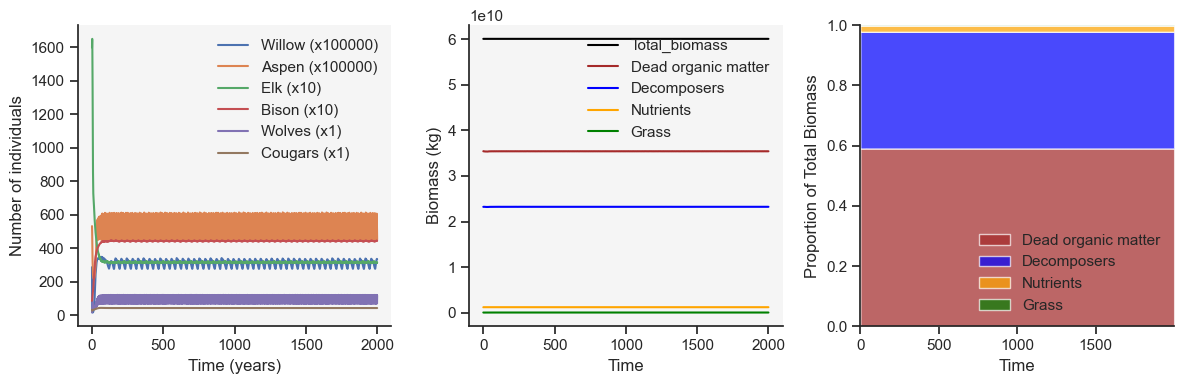

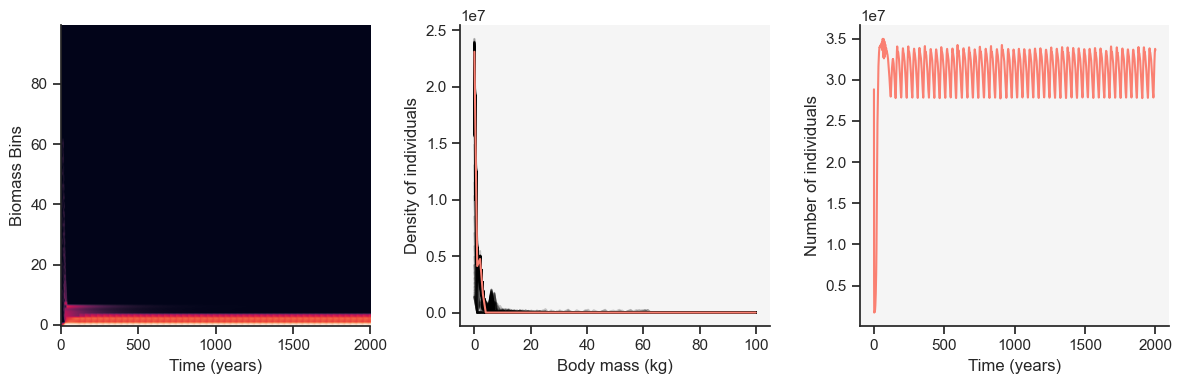

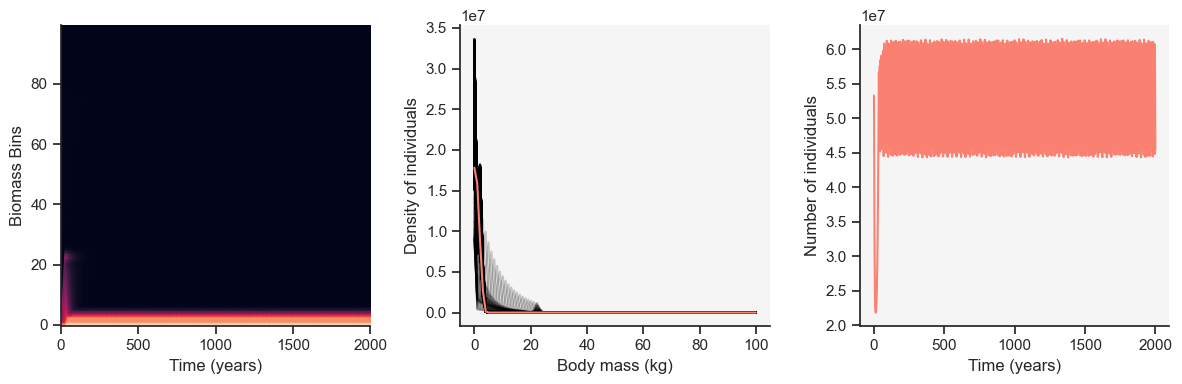

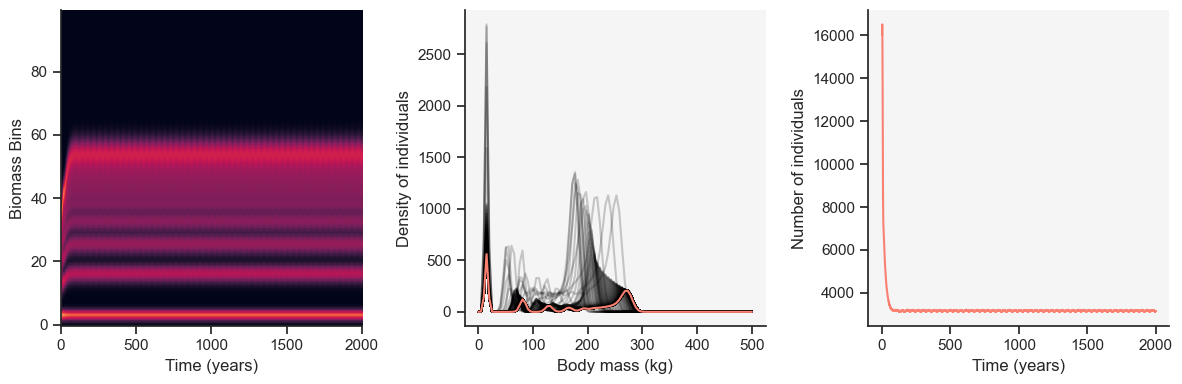

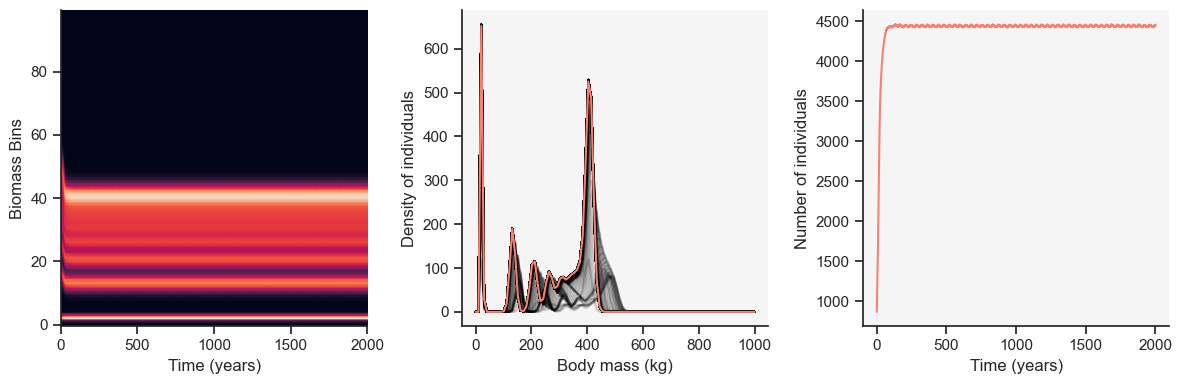

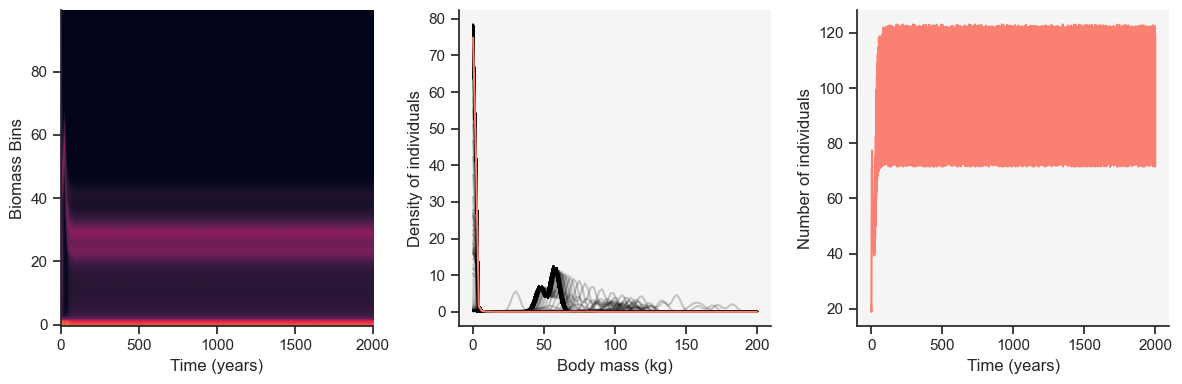

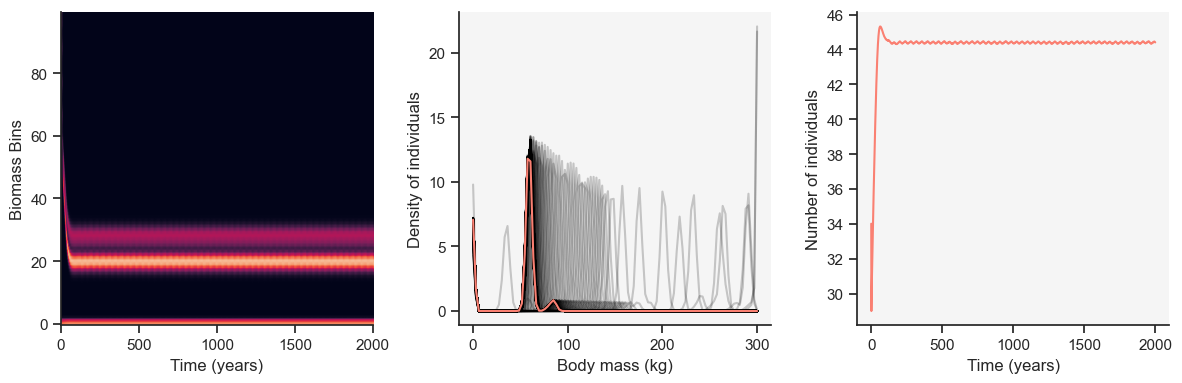

In [28]:
###############
## RUN MODEL ##
###############

## Visualise
ttheta_map = get_map(chain)
predictions_map = wrapper(ttheta_map, t_max=2000)
plot_model(predictions_map)

#
###